# Supplementary Note 3 · Additional results

The results that support the main text without belonging in it: what the residual load looks like
before any event detector is applied, what the threshold does, and the parts of the extremes
analysis the four main figures could not carry.

Artwork rules and the caption/height rule are those of Note 1. Numbering continues: **Note 3 is
S23–S33**.

| | content | figures |
|---|---|---|
| **S23** | residual load by season | 1 |
| **S24** | the Europe-wide change, zone by zone | 1 |
| **S25** | does CORDEX reproduce CERRA in energy space? | 1 |
| **S26** | threshold calibration and season-specific p95 | 1 |
| **S27** | where the paper's threshold lands inside HIGH/2050 | 1 |
| **S28** | the deficit tail, every zone and season | 1 |
| **S29** | the duration spectrum, zone by zone | 1 |
| **S30** | the diurnal cycle and its drivers, zone by zone | 1 |
| **S31** | the multi-day regime | 1 |
| **S32** | why Iberian attenuation degrades under warming | 1 |
| **S33** | what survives the HIGH/2050 build-out | 1 |


In [ ]:
%load_ext autoreload
%autoreload 2

In [2]:
import gc
import json
import time
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib import gridspec
import numpy as np
import pandas as pd
import xarray as xr

from cordex2energy_analysis.extremes_analysis import (
    mask_structural_zeros,
    attribution_change_by_model,
    compute_deficit_budget,
    compute_duration_stratified_metrics,
    compute_evening_peak_attribution,
    DEFICIT_WINDOW_HOURS,
    compute_flexibility_attenuation_metrics,
    compute_multi_day_table,
    event_anomaly_vs_hourly_climatology,
    compute_event_season_metrics,
    multi_day_event_anomaly_by_model,
    resolve_gwl_period_definitions,
)
from cordex2energy_analysis.extremes_events import (
    calculate_climatological_baseline,
    compute_continuous_system_metrics,
)
from cordex2energy_analysis.extremes_thresholds import (
    calibrate_seasonal_active_thresholds,
    compute_active_threshold,
    diagnose_threshold_coverage,
)
from cordex2energy.conversion_energy.tyndp import REALTIME_BALANCING_ZONES
from cordex2energy_analysis.figure_cache import cached, country_monthly, demand_monthly, monthly_totals
from cordex2energy_analysis.plotting_extremes import resolve_model_periods
from cordex2energy_analysis.plotting_paper import MAP_CRS, PaperStyle, load_country_geometry, _change_color
from cordex2energy_analysis.plotting_publication import (
    FS,
    europe_change_handles,
    europe_change_panel,
    europe_change_figure,
    europe_change_table,
    europe_change_summary,
    markdown_table,
    QUANTITY_CMAP,
    GWL_TITLE,
    season_label,
    sign_agreement,
    gwl_maps,
    MapRow,
    MM, SCENARIO_COLORS, SEASON_COUNT_BINS_MULTI_DAY, STORAGE_PARTS, WIDTH,
    fit_width,
    gwl_handles,
    driver_handles,
    legend_below,
    panel_binned_attenuation,
    panel_driver_attribution,
    panel_hour_of_day,
    panel_letters,
    regime_figure,
    panel_storage_stack,
    model_spread_bounds,
    storage_handles,
    publication_rc,
    save,
    tail_exceedance_figure,
)
from cordex2energy.utils.constants import REFERENCE_PERIOD

# S23 draws a country choropleth, which this notebook never did while that figure lived in the
# inputs note: the map builder, the ISO2 mapping the demand product needs, and the GWL country
# field it is built from all arrive with it.
from cordex2energy.conversion_energy.tyndp import (
    build_c2e_name_to_iso2,
    load_tyndp_country_codes,
)
from cordex2energy_analysis.extremes_analysis import (
    compute_c2e_gwl_field,
    compute_country_gwl_field,
)
# The geometry cell asserts the vectorised sign agreement matches the reference implementation.
from cordex2energy_analysis.analysis import compute_sign_agreement


In [3]:
# ── Configuration. The ANALYSIS settings are the paper's, verbatim. ─────────────────────
paths = json.load(open("../paths.json"))
PATH_PROCESSED = Path(paths["path_data_processed"])
PATH_RESIDUAL_LOAD = PATH_PROCESSED / "extremes" / "residual_load"
PATH_EXTREMES = PATH_PROCESSED / "extremes"
# S23 rebuilds the demand product and S32 reads the hydro-inflow cache. Neither path was
# needed while those two figures lived in the other notebooks.
PATH_DEMAND = PATH_PROCESSED / "energy" / "europe" / "demand"
PATH_GWL = PATH_PROCESSED / "energy" / "analysis"
FIGS = Path(paths.get("path_figs", "../figs")) / "si_note3_results"
FIGS.mkdir(parents=True, exist_ok=True)

CLIMATE_SCENARIO = "rcp85"
RUN_TAG = "DE_2050_c2edem_LOW_2050_freecool_reservoirdispatch_batteries_prosumer_sysflex_SWT120_3600"
RUN_TAG_HIGH_2050 = "DE_2050_c2edem_HIGH_2050_freecool_reservoirdispatch_batteries_prosumer_sysflex_SWT120_3600"

THRESHOLD_PERCENTILE = 95.0
EVENT_DETECTION = "spa"
WARMING_LEVELS = [1.5, 2.0, 3.0]
DURATION_BINS = {"sub_daily": (0, 24), "multi_day": (24, float("inf"))}
DURATION_LABELS = {"sub_daily": "sub-daily\n(\u2264 24 h)", "multi_day": "multi-day\n(> 24 h)"}
DURATION_TITLES = {"sub_daily": "Sub-daily", "multi_day": "Multi-day"}
ROBUSTNESS_FRACTION = 2 / 3
# "iqr" (P25-P75) is the convention for every shaded BAND and error bar in the paper. Box plots
# are unaffected: a box already means the IQR and its whiskers the classical 1.5xIQR rule, which
# `panel_event_frequency` sets directly rather than deriving from this. The previous value,
# "tukey", made the bands the Tukey whiskers while `panel_hour_of_day` drew P25-P75 from
# `spread_percentiles` regardless -- so Figure 6c's band and 3d's error bars beside it were two
# different conventions.
SPREAD = "iqr"
SHOULDER_SEASONS = ("MAM", "SON")      # the two seasons Figure 5 omits

# Figure 8's terminology and colours, reused verbatim by S27 so a reader moving between them is
# not asked to learn a second name and a second colour for the same two build-outs.
SCENARIO_LABELS = {"LOW": "LOW / 2050 (the paper)", "HIGH": "HIGH / 2050"}

SEASON_MAP = {12: "DJF", 1: "DJF", 2: "DJF", 3: "MAM", 4: "MAM", 5: "MAM",
              6: "JJA", 7: "JJA", 8: "JJA", 9: "SON", 10: "SON", 11: "SON"}
SEASON_ORDER = ["DJF", "MAM", "JJA", "SON"]
SEASON_MONTHS = {s: [m for m, name in SEASON_MAP.items() if name == s] for s in SEASON_ORDER}

# Figure 6d's and S31c's driver palette, needed by S30, which reuses their panel builder. The keys
# are the pipeline's column names; the rename is applied at the legend only.
DRIVER_PALETTE = {"Demand": "#D95F02", "PV": "#E6AB02", "Wind Onshore": "#7570B3",
                  "Wind Offshore": "#1B7C3D", "Hydro RoR": "#3182BD",
                  "Reservoir Hydro": "#08519C", "Battery": "#8B5A2B"}
DRIVER_DISPLAY = {"Reservoir Hydro": "Hydro Reservoir"}
GWL_COLORS = ["#4A90E2", "#F5A623", "#D0021B"]
ZONE_ORDER = ["Iberian_Peninsula", "South_East", "Central_Western",
              "Central_Eastern", "Nordic", "British_Isles"]
ZONE_LABELS = {"Iberian_Peninsula": "Iberia", "South_East": "South-East",
               "Central_Western": "Central-West", "Central_Eastern": "Central-East",
               "Nordic": "Nordic", "British_Isles": "British Isles"}

_main = json.load(open("paper_figures_publication.ipynb"))
_tags = {line.split('"')[1] for cell in _main["cells"] if cell["cell_type"] == "code"
         for line in cell["source"] if line.startswith("RUN_TAG =")}
assert _tags == {RUN_TAG}, f"run tag drifted from the main figures: {_tags} vs {RUN_TAG}"
print("run tag matches paper_figures_publication.ipynb")
print("figures ->", FIGS)

run tag matches paper_figures_publication.ipynb
figures -> /home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/figs/si_note3_results


In [4]:
# ── The pipeline, as a function of the run tag ──────────────────────────────────────────
def load_run(run_tag: str, *, threshold_from: str = "cerra"):
    """Load one residual-load run and prepare everything the event statistics need.

    ``threshold_from``:
      * ``"cerra"``   — calibrate the p95 deficit level on that run's own CERRA reanalysis pass.
        Correct when the *system* changes (S33: a different build-out is a different system, so its
        reference deficit distribution is different too).
      * an ``xr.DataArray`` — reuse a threshold calibrated elsewhere. Correct when the question is
        "what does this component absorb?" (S32: re-calibrating without batteries would move the
        goalposts by exactly the effect being measured).
    """
    zonal_rl, zonal_components = [], []
    for folder in sorted(PATH_RESIDUAL_LOAD.glob("*")):
        run_dir = folder / run_tag
        if not folder.is_dir() or folder.name == "cerra" or not run_dir.exists():
            continue
        model = "_".join(folder.name.split("_")[:-1])
        zonal_rl.append(xr.open_dataset(run_dir / "residual_load_zonal.nc").expand_dims(model=[model]))
        zonal_components.append(
            xr.open_dataset(run_dir / "components_zonal.nc").expand_dims(model=[model]))
    zonal_rl = xr.concat(zonal_rl, dim="model", join="outer")
    zonal_components = xr.concat(zonal_components, dim="model", join="outer")

    run_models = list(zonal_rl["model"].values)
    run_zones = [z for z in ZONE_ORDER if z in [str(x) for x in zonal_rl["zone"].values]]

    cerra_deficit = None
    if isinstance(threshold_from, str) and threshold_from == "cerra":
        cerra_dir = PATH_RESIDUAL_LOAD / "cerra" / run_tag
        cerra_rl = xr.open_dataset(cerra_dir / "residual_load_zonal.nc")
        cerra_components = xr.open_dataset(cerra_dir / "components_zonal.nc")
        shared = np.intersect1d(cerra_rl.time.values, cerra_components.time.values)
        cerra_rl, cerra_components = cerra_rl.sel(time=shared), cerra_components.sel(time=shared)
        cerra_metrics = compute_continuous_system_metrics(
            cerra_rl, cerra_components, calculate_climatological_baseline(cerra_components))
        cerra_deficit = cerra_metrics["residual_load"].where(cerra_metrics["residual_load"] > 0)
        threshold = compute_active_threshold(cerra_deficit, "PERCENTILE",
                                             percentile=THRESHOLD_PERCENTILE)
    else:
        threshold = threshold_from
        cerra_metrics = None

    by_model, components_by_model, metrics_by_model = {}, {}, {}
    for model in run_models:
        rl = zonal_rl.sel(model=model).drop_vars("model", errors="ignore").dropna("time", how="all")
        comp = (zonal_components.sel(model=model).drop_vars("model", errors="ignore")
                .dropna("time", how="all"))
        shared = np.intersect1d(rl.time.values, comp.time.values)
        by_model[model] = rl.sel(time=shared)
        components_by_model[model] = comp.sel(time=shared)
        metrics_by_model[model] = compute_continuous_system_metrics(
            by_model[model], components_by_model[model],
            calculate_climatological_baseline(
                components_by_model[model].sel(time=slice(*REFERENCE_PERIOD))))

    return dict(
        run_tag=run_tag, models=run_models, zones=run_zones,
        residual_load=by_model, components=components_by_model, metrics=metrics_by_model,
        threshold=threshold, threshold_by_model={m: threshold for m in run_models},
        cerra_deficit=cerra_deficit, cerra_metrics=cerra_metrics, zonal_rl=zonal_rl,
    )


def event_tables(run: dict, period_defs: dict):
    """The two event tables — both scored against the run's single absolute threshold.

    The seasonal one bins ANNUALLY detected events by their prevailing season, so its counts sum to
    the annual ones exactly. It no longer takes a per-season threshold dict: that argument belonged
    to the per-season detection this replaced, and leaving it here would invite that convention back.
    """
    annual = compute_duration_stratified_metrics(
        run["residual_load"], run["metrics"], run["threshold_by_model"], period_defs,
        run["models"], run["zones"], method=EVENT_DETECTION, duration_bins=DURATION_BINS)
    # ONE detection pass, each event assigned whole to its prevailing season, so the four
    # seasonal counts sum to the annual ones exactly and a boundary-straddling multi-day event is
    # not split into two sub-daily ones.
    seasonal = compute_event_season_metrics(
        run["residual_load"], run["threshold_by_model"], period_defs, run["models"], run["zones"],
        SEASON_MAP, SEASON_ORDER, method=EVENT_DETECTION, duration_bins=DURATION_BINS)
    return annual, seasonal


def remove_batteries(run: dict) -> dict:
    """The battery-free counterfactual, reconstructed from the SAME sysflex run.

    In the sysflex scheme the reservoir is dispatched FIRST and independently, then the battery
    operates on the reservoir-adjusted load. The saved
    ``battery_dispatch_gwh = RL_before_battery - RL_after_battery`` (positive = discharge), so
    adding it back recovers the pre-battery residual load with the reservoir dispatch held EXACTLY
    fixed. Loading the standalone no-battery tag instead would also change the reservoir dispatch
    (checked: Central-East reservoir 8 vs 39 TWh/yr, Nordic 175 vs 1) and confound the comparison.
    """
    residual_load, metrics = {}, {}
    for model in run["models"]:
        rl = run["residual_load"][model].copy()
        rl["residual_load"] = rl["residual_load"] + run["components"][model]["battery_dispatch_gwh"]
        residual_load[model] = rl
        metrics[model] = compute_continuous_system_metrics(
            rl, run["components"][model],
            calculate_climatological_baseline(
                run["components"][model].sel(time=slice(*REFERENCE_PERIOD))))
    return {**run, "residual_load": residual_load, "metrics": metrics}

In [5]:
# ── The paper's run, its GWL windows, and the event tables ──────────────────────────────
started = time.perf_counter()
main = load_run(RUN_TAG)
models, zones = main["models"], main["zones"]

period_defs, _, _ = resolve_gwl_period_definitions(
    warming_levels=WARMING_LEVELS, models=models, chain_meta_path="../models.json",
    gwl_yaml_path=PATH_PROCESSED / "cmip5_warming_levels_all_ens_1861_1900.yml",
    climate_scenario=CLIMATE_SCENARIO)
period_names = list(period_defs.keys())
REFERENCE, WARMEST = period_names[0], period_names[-1]
ROBUSTNESS_THRESHOLD = int(np.ceil(len(models) * ROBUSTNESS_FRACTION))

STYLE = PaperStyle(
    zones=zones, zone_labels=ZONE_LABELS, period_names=period_names,
    gwl_colors=dict(zip(period_names, GWL_COLORS)), driver_palette=DRIVER_PALETTE,
    duration_palette={},
    season_order=SEASON_ORDER, n_models=len(models),
    robustness_threshold=ROBUSTNESS_THRESHOLD, spread=SPREAD)

zone_threshold = main["threshold"]
# Cached on disk (cordex2energy_analysis.figure_cache), keyed on the run's input files, every setting
# the detector reads and a hash of the analysis code; C2E_FIGCACHE=refresh forces a rebuild.
RUN_FILES = [PATH_RESIDUAL_LOAD / folder / RUN_TAG / name
             for folder in [f"{m}_{CLIMATE_SCENARIO}" for m in models] + ["cerra"]
             for name in ("residual_load_zonal.nc", "components_zonal.nc")]
RUN_KEY = dict(run_tag=RUN_TAG, models=models, zones=zones, threshold=zone_threshold,
               periods=period_defs, reference=REFERENCE_PERIOD, method=EVENT_DETECTION,
               durations=DURATION_BINS, seasons=SEASON_MAP, season_order=SEASON_ORDER)
events_annual, events_by_season, deficit_budget, diurnal_profiles = cached(
    "note3_tables",
    lambda: (*event_tables(main, period_defs),
             *compute_deficit_budget(main["residual_load"], main["threshold_by_model"], period_defs,
                                     zones, method=EVENT_DETECTION)),
    key=RUN_KEY, files=RUN_FILES)

print(f"{len(models)} chains x {len(zones)} zones  [{time.perf_counter() - started:.0f}s]")
print(f"CERRA p{THRESHOLD_PERCENTILE:.0f} threshold (GWh / 3 h): "
      + ", ".join(f"{ZONE_LABELS[z]} {float(zone_threshold.sel(zone=z)):.0f}" for z in zones))

[cache] hit   note3_tables  (0 MB, 0s)
9 chains x 6 zones  [25s]
CERRA p95 threshold (GWh / 3 h): Iberia 77, South-East 137, Central-West 434, Central-East 192, Nordic 57, British Isles 145


In [6]:
# ── The country geometry the choropleth figure draws ────────────────────────────────────
# ETRS89-LAEA (EPSG:3035), the EU's equal-area projection: drawn areas are true areas. The earlier
# lon/lat maps were stretched to their panel box and inflated the north.
countries = load_country_geometry(
    PATH_PROCESSED / "maps" / "natural_earth" / "ne_50m_admin_0_countries.geojson", crs=MAP_CRS)
# Simplified geometry for the choropleth figures, as in Figures 2 and 3: at ~55 mm per map a 0.02 deg
# displacement is ~0.02 mm, an order of magnitude below print resolution, and it halves the vector
# file. The gridded figures draw only country BOUNDARIES, so they use it too.
countries_print = countries.copy()
countries_print["geometry"] = countries.geometry.simplify(2000.0)   # metres, ~0.02 deg
assert set(countries_print["ISO2"]) == set(countries["ISO2"]), "simplification dropped a country"

# The hatching uses the vectorised sign agreement: analysis.compute_sign_agreement goes through
# apply_ufunc(vectorize=True), i.e. a Python loop over every grid cell, which costs 7 s per 426x510
# field and 84 s per six-row figure. Assert the two agree exactly rather than trusting the swap.
_probe = xr.DataArray(np.random.RandomState(0).randn(len(models), 40, 50),
                      dims=("model", "lat", "lon")).where(
                          np.random.RandomState(1).rand(len(models), 40, 50) > 0.15)
assert (compute_sign_agreement(_probe, model_dim="model").values
        == sign_agreement(_probe).values).all(), "the fast sign agreement is not the reference one"

print(f"{len(models)} chains | robustness {ROBUSTNESS_THRESHOLD}/{len(models)} "
      f"| periods {period_names}")

9 chains | robustness 6/9 | periods ['+1.5°C', '+2.0°C', '+3.0°C']


In [7]:
# ── The exceedance tables behind S28 and S30 ────────────────────────────────────────────
# Built by the SAME code as paper_figures_publication.ipynb, so the supplement and the main text
# argue from one table and differ only in which seasons are selected from it. Note that S28 is drawn
# by `tail_exceedance_figure`, the builder Figure 5 used BEFORE it was restructured around the zone
# map and the duration spectrum; the two figures no longer share a layout, only these inputs.
# Detector-free (values above the zone threshold), so they can sit beside the survival curves
# without a consistency caveat.
started = time.perf_counter()
rows = []
for model in models:
    series = main["residual_load"][model]["residual_load"]
    for period in period_names:
        window = resolve_model_periods(period_defs, model).get(period)
        if window is None:
            continue
        chunk = series.sel(time=slice(*window))
        times = pd.DatetimeIndex(chunk["time"].values)
        n_years = len(np.unique(times.year))
        for zone in zones:
            over = chunk.sel(zone=zone).values > float(zone_threshold.sel(zone=zone))
            for season in SEASON_ORDER:
                in_season = np.isin(times.month, SEASON_MONTHS[season])
                for hour in np.unique(times.hour):
                    at_hour = times.hour == hour
                    rows.append(dict(model=model, period=period, zone=zone, season=season,
                                     hour=int(hour),
                                     hours_yr=3.0 * int((over & in_season & at_hour).sum())
                                     / n_years))
hour_exceedance = pd.DataFrame(rows)
season_exceedance = (hour_exceedance
                     .groupby(["model", "period", "zone", "season"], as_index=False)["hours_yr"]
                     .sum())

# freq_per_year x avg_duration_h IS extreme-event hours per year (same 3 h step, same detector).
events_by_season = events_by_season.assign(
    hours_yr=events_by_season["freq_per_year"] * events_by_season["avg_duration_h"])
# `events_by_season` carries one row per (model, period, zone, season, duration_class). It is passed
# whole to S31 rather than pre-aggregated, so the panel takes the median across chains itself and no
# zone or class is summed away before it gets there.
print(f"exceedance tables: {len(hour_exceedance):,} rows | burden table {events_by_season.shape} "
      f"[{time.perf_counter() - started:.0f}s]")


exceedance tables: 5,184 rows | burden table (1296, 9) [15s]


In [8]:
# ── Two things the dropped figures used to build ────────────────────────────────────────
# `multi_day_events` and `panel_zone_season_counts` were defined inside the cells that drew the
# old S23 (multi-day composition) and S27 (seasonal counts). Those figures are not in this note,
# but S31 and S33 use both, so the definitions move here rather than the figures being kept for
# the sake of their side effects.

# ── What a multi-day event is made of, against its own season's mean ────────────────────
# The event-conditioned columns come from the same pass that counts the events, so this costs one
# table build and no second event detection.
started = time.perf_counter()
multi_day_events, _ = compute_multi_day_table(
    main["residual_load"], main["components"], main["threshold_by_model"], period_defs, zones,
    SEASON_MAP, SEASON_ORDER, method=EVENT_DETECTION, attribution_seasons=SEASON_ORDER)
# attribution_seasons defaults to ("DJF", "JJA"); S31c needs all four, and this cell builds the only
# copy of the table. Figure 6 selects two seasons from it, so the extra columns cost it nothing.
assert {"MAM_Demand", "SON_RL"} <= set(multi_day_events.columns), \
    "the attribution table is still two-season; S31c would silently drop MAM and SON"
print(f"multi-day table [{time.perf_counter() - started:.0f}s]")


def panel_zone_season_counts(axes, table, style, seasons, duration_class):
    """Events per year by zone, one sub-axis per season, three warming-level bars per zone."""
    positions = np.arange(len(style.zones))
    grid = table[table.duration_class == duration_class].groupby(
        ["season", "zone", "period"])["freq_per_year"].median()

    def value(season, zone, period):
        got = grid.get((season, zone, period), np.nan)
        return 0.0 if got is None or not np.isfinite(got) else float(got)

    for ax, season in zip(axes, seasons):
        top = 0.0
        for k, period in enumerate(period_names):
            values = [value(season, z, period) for z in style.zones]
            top = max(top, max(values))
            ax.bar(positions + (k - 1) * 0.26, values, 0.24, color=style.gwl_colors[period],
                   edgecolor="white", linewidth=0.3, zorder=2)
        for i, zone in enumerate(style.zones):
            if max(value(season, zone, p) for p in period_names) <= 1e-9:
                ax.annotate("no events", xy=(i, 0), xytext=(0, 3), textcoords="offset points",
                            ha="center", va="bottom", rotation=90, fontsize=FS["tick"], color="0.55")
        ax.set_ylim(0, max(top, 1.0) * 1.18)
        ax.set_xticks(positions)
        ax.set_xticklabels(style.labels(), fontsize=FS["tick"], rotation=90, va="top", ha="center")
        ax.set_xlim(-0.6, len(style.zones) - 0.4)
        ax.set_title(season_label(season), fontsize=FS["label"])
        ax.tick_params(labelsize=FS["tick"])
        ax.grid(True, axis="y", color="0.93", lw=0.3)
        ax.set_axisbelow(True)

multi-day table [4s]


## 1 · S23: residual load by season

Before any event detector: the quantity everything downstream is computed from, and how warming
moves it season by season.

> **Supplementary Figure 23 | Residual load by season.** Rows are the four meteorological seasons,
> columns the level at +1.5 °C and the median change across nine chains at +2.0 °C and +3.0 °C.
> National totals. Residual load is drawn as an **absolute** change in TWh, not a percentage: it
> passes through zero, where a percentage is undefined. The four rows share one absolute scale.
> Hatching marks countries where fewer than six of nine chains agree on the sign.

In [10]:
# ── The demand product, rebuilt from the raw hourly output ──────────────────────────────
# NOT from energy/analysis/c2e_cache/c2e_{heating,cooling}_rcp85.nc: that cache predates the
# adopted demand model. This is the same construction paper_figures_publication.ipynb uses.
started = time.perf_counter()


# MONTHLY sums of the DAILY-MEAN demand (GW), cached on disk (cordex2energy_analysis.figure_cache).
# Every field below slices whole-year GWL windows and whole months, so monthly totals are an exact
# substitute for the daily series (checked to 1e-9), and a rerun skips the hourly files entirely.
demand_by_month = demand_monthly(PATH_DEMAND, models, CLIMATE_SCENARIO)
NAME_TO_ISO2 = build_c2e_name_to_iso2(load_tyndp_country_codes(
    PATH_EXTREMES / "tyndp" / "Demand_Scenarios_TYNDP_2024_After_Public_Consultation.xlsb"))
for name, array in demand_by_month.items():
    demand_by_month[name] = array.assign_coords(
        country=[NAME_TO_ISO2.get(str(c), str(c)) for c in array["country"].values])

residual_by_model = country_monthly(
    {m: PATH_EXTREMES / "residual_load" / f"{m}_{CLIMATE_SCENARIO}" / RUN_TAG for m in models},
    ("residual_load.nc",))
print(f"demand product loaded [{time.perf_counter() - started:.0f}s]")

# Figure 3's edges, so the same quantity sits on the same scale in the SI and the main text.
# Measured maxima across the nine chains: heating 56 %, cooling 226 %, residual load 12.1 TWh/yr.
DEMAND_BINS = {
    "Heating demand": [-50, -30, -20, -15, -10, -1, 1, 10, 15, 20, 30, 50],
    "Cooling demand": [-200, -150, -100, -50, -25, -1, 1, 25, 50, 100, 150, 200],
    "Residual load": [-10, -5, -2, -0.5, 0.5, 2, 5, 10],            # TWh/yr, ABSOLUTE
}
# A season carries a fraction of the annual change, so the absolute residual-load edges are halved
# for the seasonal figure; the per-bin counts printed below confirm nothing piles into the arrows.
DEMAND_BINS_SEASONAL = {**DEMAND_BINS, "Residual load": [-5, -2, -1, -0.25, 0.25, 1, 2, 5]}
assert all(np.allclose(sorted(-np.array(e)), e)
           for e in list(DEMAND_BINS.values()) + list(DEMAND_BINS_SEASONAL.values())), \
    "every edge set must be symmetric about zero"


DEMAND_ROWS = ["Heating demand", "Cooling demand", "Residual load"]
# Residual load is BrBG_r for the same reason as Figure 3: it is the only DIVERGING level here,
# and sharing RdBu_r with its own change column made the two read as one thing. Teal for
# surplus, brown for deficit; the change columns own red/blue.
DEMAND_CMAP = QUANTITY_CMAP          # one definition, shared with Figures 2 and 3
# scale=24e-3: the monthly totals are sums of daily means in GW, so a period-mean total is
# GW*24 h = GWh -> TWh.
DEMAND_FN = {
    "Heating demand": lambda p, m: compute_c2e_gwl_field(demand_by_month, period_defs, p, "heating",
                                                         scale=24e-3, months=m),
    "Cooling demand": lambda p, m: compute_c2e_gwl_field(demand_by_month, period_defs, p, "cooling",
                                                         scale=24e-3, months=m),
    # NOT mask_structural_zeros here: residual load can legitimately pass through zero, and a
    # country that happens to balance exactly must not be greyed out as though it had no data.
    "Residual load": lambda p, m: compute_country_gwl_field(
        residual_by_model, period_defs, p, lambda d: d["residual_load"], months=m),
}

# Computed once. Each is a 20-year reduction over 3-hourly country series, so rebuilding them per
# figure (and again in the verification cell) would triple the runtime.
started = time.perf_counter()
demand_annual = {label: {p: fn(p, None) for p in period_names} for label, fn in DEMAND_FN.items()}
demand_seasonal = {label: {s: {p: fn(p, SEASON_MONTHS[s]) for p in period_names}
                           for s in SEASON_ORDER}
                   for label, fn in DEMAND_FN.items()}
print(f"demand and residual-load fields built [{time.perf_counter() - started:.0f}s]")


def demand_row(label, *, season=None, unit_suffix="yr", row_label=None):
    bins = (DEMAND_BINS_SEASONAL if season is not None else DEMAND_BINS)[label]
    cache = demand_annual[label] if season is None else demand_seasonal[label][season]
    absolute = label == "Residual load"
    return MapRow(
        label=row_label or label, field=lambda p, c=cache: c[p], kind="country",
        cmap=DEMAND_CMAP[label],
        # `unit_suffix=None` for a row that IS one season: the row label already says which, so
        # "TWh / season" on the colorbar states it twice.
        unit="TWh" if unit_suffix is None else f"TWh {unit_suffix}$^{{-1}}$",
        change="absolute" if absolute else "percent", bins=bins,
        abs_center=0 if absolute else None,
        # No override: the builder's default is now RdBu_r for every row, which is the rule
        # Figures 2 and 3 carry — red is more of the quantity the row plots.
        # No clabel override: the default is already "change (TWh / <unit>)". The sign
        # convention lives in the caption, matching Figures 2 and 3.
        clabel=None)

[cache] hit   demand_monthly  (7 MB, 0s)
[cache] hit   country_monthly_residual_load  (3 MB, 0s)
demand product loaded [0s]
demand and residual-load fields built [4s]


  S23_residual_load_seasonal   151.3 x 159.7 mm   panel 36.0 mm   pdf 975 kB  png 1737 kB


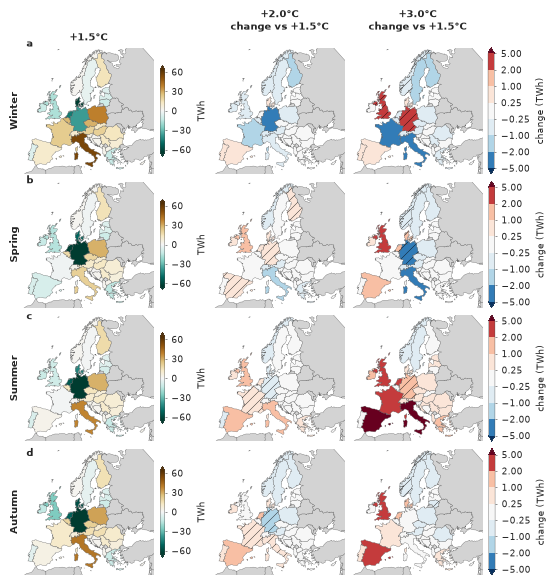

In [11]:
with publication_rc():
    rows = [demand_row("Residual load", season=season, unit_suffix=None, row_label=season_label(season))
            for season in SEASON_ORDER]
    fig, row_axes = gwl_maps(rows, countries_print, STYLE, sign_agreement,
                             height_mm=162, share_abs_scale=True)
    panel_letters(fig, list(zip("abcd", row_axes)), inside=True)
    save(fig, "S23_residual_load_seasonal", FIGS)
plt.show()

## 2 · S24: the Europe-wide change, zone by zone

Figure 4 summed over every country. Split into the six balancing zones it shows where each term of
the Europe-wide change comes from, and that the summer rise in residual load is concentrated in the
south.

> **Supplementary Figure 24 | Change in energy quantities between +1.5 °C and +3.0 °C, by balancing
> zone.** As Figure 4, for each balancing zone (rows): annual (left), winter (December–February,
> centre) and summer (June–August, right). Each quantity is summed over the zone's countries and the
> change is formed per chain; the darker box gives the interquartile range across the nine chains,
> its paler extensions the minimum to maximum, and the dark line the median. Demand in orange and
> supply in blue, lighter for the components and darker for the totals; the residual load in grey. Each zone
> row has its own horizontal scale, with winter and summer sharing one. The six zones sum to Figure 4
> in every chain. Supplementary Table S1 gives the values.


[cache] hit   country_monthly_residual_load+components  (33 MB, 0s)
zonal changes [31s]
six zones close on the Europe-wide change in every chain
  S24_europe_change_by_zone    179.7 x 198.3 mm   panel 21.4 mm   pdf 52 kB  png 423 kB


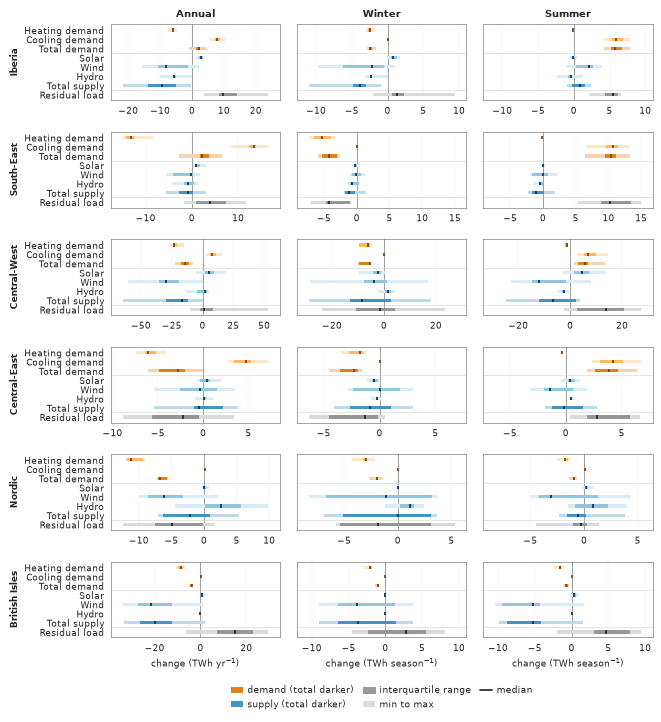

In [13]:
# ── S24: Figure 4 resolved by balancing zone ─────────────────────────────────────────────────────────
# The SAME inputs and builders as Figure 4 (`europe_change_table`, `europe_change_panel`): the demand
# product loaded above and the paper run's per-country output files, opened as the main notebook
# opens them, so the two figures draw one table.
# Monthly totals from the disk cache -- the SAME entry the main notebook's Figure 4 reads.
country_output_by_model = country_monthly(
    {m: PATH_EXTREMES / "residual_load" / f"{m}_{CLIMATE_SCENARIO}" / RUN_TAG for m in models},
    ("residual_load.nc", "components.nc"))
EUROPE_COLUMNS = {"Annual": None, "DJF": SEASON_MONTHS["DJF"], "JJA": SEASON_MONTHS["JJA"]}
_SUPPLY = ("gen_pv", "gen_wind_on", "gen_wind_off", "gen_hydro_ror", "reservoir_dispatch_gwh",
           "battery_dispatch_gwh")


def _country(expression):
    return lambda p, m: compute_country_gwl_field(country_output_by_model, period_defs, p,
                                                  expression, months=m)


# The thermal rows are summed over the residual-load run's countries ONLY, so every row covers one
# domain: the demand product also carries Ukraine and Kosovo (~7 % of European cooling), which no
# balancing zone and no power-system row includes.
RUN_COUNTRIES = [str(c) for c in country_output_by_model[models[0]]["country"].values]


def _demand(variable):
    def field(p, m):
        out = compute_c2e_gwl_field(demand_by_month, period_defs, p, variable, scale=24e-3, months=m)
        missing = set(RUN_COUNTRIES) - set(map(str, out["country"].values))
        assert not missing, f"run countries missing from the demand product: {sorted(missing)}"
        return out.sel(country=RUN_COUNTRIES)
    return field


EUROPE_ROWS = [
    ("Heating demand", _demand("heating")),
    ("Cooling demand", _demand("cooling")),
    ("Total demand", _country(lambda d: d["total_demand"])),
    ("Solar", _country(lambda d: d["gen_pv"])),
    ("Wind", _country(lambda d: d["gen_wind_on"] + d["gen_wind_off"])),
    ("Hydro", _country(lambda d: d["gen_hydro_ror"] + d["reservoir_dispatch_gwh"])),
    ("Total supply", _country(lambda d: sum(d[v] for v in _SUPPLY))),
    ("Residual load", _country(lambda d: d["residual_load"])),
]
EUROPE_LABELS = [label for label, _ in EUROPE_ROWS]

started = time.perf_counter()
europe_change = europe_change_table(EUROPE_ROWS, EUROPE_COLUMNS, REFERENCE, WARMEST)
zone_change = {zone: europe_change_table(EUROPE_ROWS, EUROPE_COLUMNS, REFERENCE, WARMEST,
                                         members=REALTIME_BALANCING_ZONES[zone])
               for zone in ZONE_ORDER}
print(f"zonal changes [{time.perf_counter() - started:.0f}s]")

# Closure: per chain, the six zones sum to the Europe-wide change, exactly, in every row -- the
# thermal rows included, now that they are restricted to the run's (all zoned) countries.
for (column, label), table in europe_change.items():
    total = sum(zone_change[z][column, label].twh for z in ZONE_ORDER)
    gap = float((total - table.twh).abs().max())
    scale = max(1.0, float(table.twh.abs().max()))
    assert gap < 1e-6 * scale, f"{column} {label}: zones do not sum to Europe ({gap:.3g} TWh)"
print("six zones close on the Europe-wide change in every chain")


def figure_s24():
    columns = list(EUROPE_COLUMNS)
    fig, axes = plt.subplots(len(ZONE_ORDER), len(columns), figsize=(WIDTH, 205 * MM),
                             sharey=True, gridspec_kw={"wspace": 0.10, "hspace": 0.42})
    for r, zone in enumerate(ZONE_ORDER):
        change = zone_change[zone]
        spans = {}
        for column in columns:
            lo = min(change[column, l].twh.min() for l in EUROPE_LABELS)
            hi = max(change[column, l].twh.max() for l in EUROPE_LABELS)
            spans[column] = (min(lo, 0.0), max(hi, 0.0))
        joint = (min(spans["DJF"][0], spans["JJA"][0]), max(spans["DJF"][1], spans["JJA"][1]))
        spans["DJF"] = spans["JJA"] = joint
        for c, column in enumerate(columns):
            ax = axes[r, c]
            europe_change_panel(ax, change, EUROPE_LABELS, column, span=spans[column])
            if r == 0:
                ax.set_title(season_label(column), fontsize=FS["title"], fontweight="bold")
            if c == 0:
                ax.set_ylabel(ZONE_LABELS[zone], fontsize=FS["label"], fontweight="bold")
                ax.set_yticklabels(EUROPE_LABELS, fontsize=FS["tick"])
            if r == len(ZONE_ORDER) - 1:
                unit = "TWh yr$^{-1}$" if column == "Annual" else "TWh season$^{-1}$"
                ax.set_xlabel(f"change ({unit})", fontsize=FS["label"])
    fit_width(fig)
    legend_below(fig, list(axes[-1]), *europe_change_handles(), ncol=3)
    return fig


with publication_rc():
    fig = figure_s24()
    save(fig, "S24_europe_change_by_zone", FIGS)
plt.show()


### Supplementary Table S1

> **Supplementary Table 1 | Change in energy quantities between +1.5 °C and +3.0 °C, by balancing
> zone and time scale.** The values Supplementary Fig. S24 draws, as Table 1 for each balancing zone:
> **a**, annual (TWh yr⁻¹); **b**, winter (December–February, DJF) and **c**, summer (June–August,
> JJA), in TWh season⁻¹. Each quantity is summed over the zone's countries and the change is
> formed per chain; median, quartiles (P25, P75), minimum and maximum across the nine chains, and
> the number of chains whose change has the sign of the median. A dash marks a median change below
> 0.05 TWh.


In [15]:
# ── Supplementary Table S1 · the values Supplementary Fig. S24 draws, per zone and time scale ──
# Same per-chain tables as the figure (`zone_change`); one table per time scale, rows grouped by zone.
TABLE_S1_PARTS = {"Annual": "a · annual (TWh yr⁻¹)", "DJF": "b · winter, DJF (TWh season⁻¹)",
                  "JJA": "c · summer, JJA (TWh season⁻¹)"}
zone_summary = {zone: europe_change_summary(zone_change[zone], EUROPE_LABELS, EUROPE_COLUMNS)
                for zone in ZONE_ORDER}
table_s1 = {column: pd.concat({ZONE_LABELS[z]: zone_summary[z][column] for z in ZONE_ORDER},
                              names=["zone", "quantity"])
            for column in EUROPE_COLUMNS}
for column, frame in table_s1.items():
    print(f"Supplementary Table S1{TABLE_S1_PARTS[column]}\n")
    print(markdown_table(frame), end="\n\n")
pd.concat(table_s1, names=["time scale"]).to_csv(FIGS / "table_s1_europe_change_by_zone.csv",
                                                  float_format="%.2f")


Supplementary Table S1a · annual (TWh yr⁻¹)

| zone | quantity | median | P25 | P75 | min | max | sign agreement |
|:---|:---|---:|---:|---:|---:|---:|---:|
| Iberia | Heating demand | −5.9 | −6.4 | −5.7 | −7.5 | −4.6 | 9/9 |
|  | Cooling demand | +7.9 | +7.1 | +8.8 | +5.6 | +10.5 | 9/9 |
|  | Total demand | +2.2 | +1.1 | +2.7 | −0.8 | +4.7 | 8/9 |
|  | Solar | +2.7 | +2.1 | +3.5 | +1.2 | +3.8 | 9/9 |
|  | Wind | −8.2 | −10.6 | −1.3 | −15.5 | +2.2 | 8/9 |
|  | Hydro | −5.6 | −5.7 | −4.9 | −10.0 | 0.0 | 9/9 |
|  | Total supply | −9.3 | −13.8 | −5.0 | −21.8 | −0.4 | 9/9 |
|  | Residual load | +9.7 | +8.5 | +14.0 | +3.7 | +24.0 | 9/9 |
| South-East | Heating demand | −13.1 | −14.2 | −12.6 | −15.0 | −8.3 | 9/9 |
|  | Cooling demand | +13.5 | +12.4 | +13.8 | +8.6 | +16.6 | 9/9 |
|  | Total demand | +2.1 | +1.8 | +3.7 | −2.8 | +6.5 | 8/9 |
|  | Solar | +0.8 | +0.6 | +1.7 | +0.3 | +3.2 | 9/9 |
|  | Wind | −0.2 | −4.0 | +0.3 | −5.6 | +1.8 | 5/9 |
|  | Hydro | −0.9 | −1.6 | +0.6 | −4.4 | +1.2 |

## 3 · S25: does CORDEX reproduce CERRA in energy space?

**The paper's most attackable assumption.** The deficit threshold is the 95th percentile of the
positive residual load in the **CERRA** reanalysis, and it is then applied to **CORDEX**. If the two
disagree about the reference-period residual load, every event count in the paper inherits that
bias. So, per zone: the reference-period residual-load distribution of the nine chains against
CERRA's, and the p95 threshold each of them implies. The bias is printed, not buried.

> **Supplementary Figure 25 | CORDEX against CERRA in energy space, reference period.**
> **a**, Probability density of the zonal residual load over the +1.5 °C reference window for each
> of the six balancing zones (columns). The shaded envelope spans the nine EURO-CORDEX chains and
> the solid line is their median; the dashed black line is the CERRA reanalysis over the same
> quantity. **b**, The p95 deficit threshold each dataset implies: the box summarises the nine
> per-chain thresholds, the points are the individual chains, and the dashed line is the CERRA value
> the paper uses. The annotation gives the bias of the nine-chain median against CERRA, positive
> where the chains imply a higher deficit level than the reanalysis.

  S25_cordex_vs_cerra          179.8 x  92.9 mm   panel 36.6 mm   pdf 61 kB  png 412 kB
Threshold bias, CORDEX (9-chain median) against CERRA:
         zone  cerra  cordex_median  bias_pct
       Iberia   76.9           73.7      -4.2
   South-East  137.2          141.2       2.9
 Central-West  434.3          453.3       4.4
 Central-East  192.1          192.6       0.2
       Nordic   57.0           58.4       2.5
British Isles  145.2          140.8      -3.1


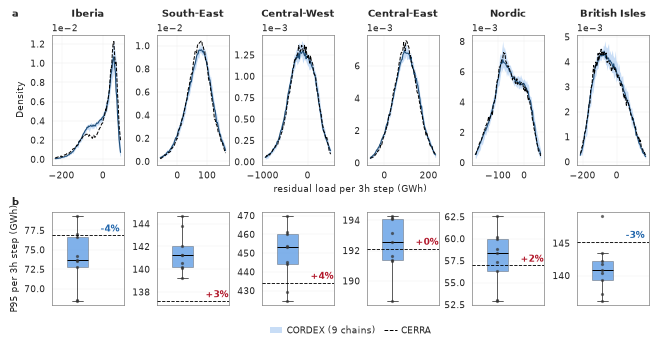

In [17]:
# ── The CORDEX reference-period residual load, and the threshold each chain would imply ─
cordex_reference, cordex_threshold = {}, {}
for model in models:
    window = period_defs[REFERENCE][model]
    reference_slice = main["metrics"][model].sel(time=slice(str(window[0]), str(window[1])))
    cordex_reference[model] = reference_slice
    deficit = reference_slice["residual_load"].where(reference_slice["residual_load"] > 0)
    cordex_threshold[model] = compute_active_threshold(deficit, "PERCENTILE",
                                                       percentile=THRESHOLD_PERCENTILE)

cerra_reference = compute_continuous_system_metrics(
    *[xr.open_dataset(PATH_RESIDUAL_LOAD / "cerra" / RUN_TAG / f)
      for f in ("residual_load_zonal.nc", "components_zonal.nc")],
    calculate_climatological_baseline(
        xr.open_dataset(PATH_RESIDUAL_LOAD / "cerra" / RUN_TAG / "components_zonal.nc")))


def figure_s25():
    fig, axes = plt.subplots(2, len(zones), figsize=(WIDTH, 82 * MM), squeeze=False,
                             gridspec_kw={"hspace": 0.42, "wspace": 0.46,
                                          "height_ratios": [1.0, 0.72]})
    bias_rows = []
    for col, zone in enumerate(zones):
        ax = axes[0, col]
        cerra_values = cerra_reference["residual_load"].sel(zone=zone).values
        cerra_values = cerra_values[np.isfinite(cerra_values)]
        edges = np.linspace(*np.percentile(cerra_values, [0.5, 99.5]), 90)
        centres = 0.5 * (edges[:-1] + edges[1:])

        per_chain = np.vstack([
            np.histogram(dataset["residual_load"].sel(zone=zone).values[
                np.isfinite(dataset["residual_load"].sel(zone=zone).values)],
                bins=edges, density=True)[0]
            for dataset in cordex_reference.values()])
        ax.fill_between(centres, per_chain.min(axis=0), per_chain.max(axis=0),
                        color="#4A90E2", alpha=0.30, lw=0, label=f"CORDEX ({len(models)} chains)")
        ax.plot(centres, np.median(per_chain, axis=0), color="#1F4E79", lw=0.9)
        ax.plot(centres, np.histogram(cerra_values, bins=edges, density=True)[0],
                color="black", lw=0.8, ls="--", label="CERRA")
        # Density ticks kept (review): each zone on its own scale, so each panel carries its own.
        ax.ticklabel_format(axis="y", style="sci", scilimits=(-2, 3))
        ax.yaxis.get_offset_text().set_fontsize(FS["tick"])
        ax.set_title(ZONE_LABELS[zone], fontsize=FS["title"], fontweight="bold")
        ax.tick_params(labelsize=FS["tick"])
        ax.grid(True, axis="x", color="0.93", lw=0.3)
        ax.set_axisbelow(True)
        if col == 0:
            ax.set_ylabel("Density", fontsize=FS["label"])

        ax = axes[1, col]
        chain_thresholds = [float(cordex_threshold[m].sel(zone=zone)) for m in models]
        cerra_thr = float(zone_threshold.sel(zone=zone))
        box = ax.boxplot([chain_thresholds], positions=[0], widths=0.5, patch_artist=True,
                         showfliers=False, medianprops=dict(color="black", lw=0.8))
        for patch in box["boxes"]:
            patch.set_facecolor("#4A90E2")
            patch.set_alpha(0.7)
            patch.set_edgecolor("0.25")
            patch.set_lw(0.4)
        for element in ("whiskers", "caps"):
            for line in box[element]:
                line.set_lw(0.5)
        ax.plot(np.zeros(len(chain_thresholds)), chain_thresholds, "o", ms=1.6, color="0.2",
                alpha=0.6, zorder=3)
        ax.axhline(cerra_thr, color="black", ls="--", lw=0.7, zorder=4)
        bias = 100 * (np.median(chain_thresholds) - cerra_thr) / cerra_thr
        ax.annotate(f"{bias:+.0f}%", xy=(0.55, cerra_thr), xytext=(0, 3),
                    textcoords="offset points", fontsize=FS["tick"], fontweight="bold",
                    color=_change_color(bias))
        ax.set_xticks([])
        ax.set_xlim(-0.6, 1.1)
        ax.tick_params(labelsize=FS["tick"])
        ax.grid(True, axis="y", color="0.93", lw=0.3)
        ax.set_axisbelow(True)
        if col == 0:
            ax.set_ylabel("P95 per 3h step (GWh)", fontsize=FS["label"])
        bias_rows.append(dict(zone=ZONE_LABELS[zone], cerra=round(cerra_thr, 1),
                              cordex_median=round(float(np.median(chain_thresholds)), 1),
                              bias_pct=round(bias, 1)))

    fit_width(fig)
    fig.canvas.draw()
    renderer, inv = fig.canvas.get_renderer(), fig.transFigure.inverted()
    # ONE x-label under row a. Six copies of the same sentence under six 27 mm columns is the
    # widest thing in the row and it is what opened the gap between a and b.
    boxes = [a.get_tightbbox(renderer).transformed(inv) for a in axes[0]]
    fig.text(0.5 * (axes[0, 0].get_position().x0 + axes[0, -1].get_position().x1),
             min(b.y0 for b in boxes) - 3.0 / 72 / fig.get_figheight(),
             "residual load per 3h step (GWh)", ha="center", va="top", fontsize=FS["label"])
    panel_letters(fig, [("a", axes[0, 0]), ("b", axes[1, 0])])
    # One dashed entry, not two: the same black dashed line means CERRA in both rows, as the
    # distribution in a and as the p95 it implies in b. Two legend entries for one mark read as
    # two different marks.
    handles, labels = axes[0, 0].get_legend_handles_labels()
    legend_below(fig, list(axes[1]), handles, labels, ncol=2)
    fig.bias_table = pd.DataFrame(bias_rows)
    return fig


with publication_rc():
    fig = figure_s25()
    save(fig, "S25_cordex_vs_cerra", FIGS)
print("Threshold bias, CORDEX (9-chain median) against CERRA:")
print(fig.bias_table.to_string(index=False))
plt.show()

## 4 · S26: threshold calibration and coverage

How the single absolute deficit level per zone is set, and what the rejected alternative would have
been. The paper scores every warming level against one annual, season-independent CERRA p95 per
zone. A season-specific p95 was considered and rejected: it re-baselines each season to its own
tail, so a season whose deficits grow would keep the same 5 % exceedance by construction and the
seasonal redistribution the paper reports would be normalised away.

> **Supplementary Figure 26 | The season-specific CERRA p95 deficit levels that the paper does not
> use.** Each cell is the 95th percentile of the positive residual load in the CERRA reanalysis for
> one balancing zone and one meteorological season, in GWh per 3h step. The paper instead applies a
> single annual p95 per zone, shown in Supplementary Fig. S25b, to every season and every warming
> level, so that a change in event count is a change in the physical system and not in the yardstick.

Annual coverage (CERRA):
             zone season  positive_fraction  threshold_gwh  threshold_floored_gwh  degenerate
    British_Isles    ALL                1.0     145.230301             145.230301       False
  Central_Eastern    ALL                1.0     192.133559             192.133559       False
  Central_Western    ALL                1.0     434.287476             434.287476       False
Iberian_Peninsula    ALL                1.0      76.870321              76.870321       False
           Nordic    ALL                1.0      56.956913              56.956913       False
       South_East    ALL                1.0     137.211302             137.211302       False
  S26_threshold_calibration    109.8 x  50.1 mm   panel 46.2 mm   pdf 38 kB  png 107 kB


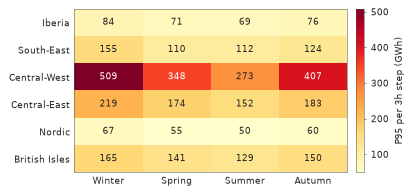

In [19]:
coverage = diagnose_threshold_coverage(main["cerra_deficit"], thresholds=zone_threshold)
print("Annual coverage (CERRA):")
print(coverage.to_string(index=False))

seasonal_thresholds, _ = calibrate_seasonal_active_thresholds(
    main["cerra_deficit"], zones, SEASON_ORDER, SEASON_MONTHS, "PERCENTILE",
    percentile=THRESHOLD_PERCENTILE)


def figure_s26():
    """A plain imshow rather than sns.heatmap: seaborn writes its own rcParams, which would win
    over publication_rc() and put 10 pt type into a 5-7 pt figure."""
    table = np.array([[float(seasonal_thresholds[str(z)][s]) for s in SEASON_ORDER]
                      for z in zones])
    fig, ax = plt.subplots(figsize=(WIDTH * 0.52, 52 * MM))
    image = ax.imshow(table, cmap="YlOrRd", aspect="auto")
    ax.set_xticks(range(len(SEASON_ORDER)), [season_label(s) for s in SEASON_ORDER], fontsize=FS["label"])
    ax.set_yticks(range(len(zones)), [ZONE_LABELS[z] for z in zones], fontsize=FS["label"])
    ax.tick_params(length=0)
    ax.grid(False)      # the shared white grid is drawn ON TOP of the cells and through the numbers
    for row in range(table.shape[0]):
        for col in range(table.shape[1]):
            value = table[row, col]
            # Contrast against the cell, not a fixed colour: YlOrRd runs from near-white to a deep
            # red, so one ink colour is unreadable at one end of the ramp or the other.
            shade = (value - table.min()) / max(table.max() - table.min(), 1e-9)
            ax.text(col, row, f"{value:.0f}", ha="center", va="center", fontsize=FS["tick"],
                    color="white" if shade > 0.6 else "0.15")
    bar = fig.colorbar(image, ax=ax, fraction=0.05, pad=0.03)
    bar.set_label("P95 per 3h step (GWh)", fontsize=FS["label"])
    bar.ax.tick_params(labelsize=FS["tick"])
    bar.outline.set_linewidth(0.4)
    fit_width(fig, target_mm=110)
    return fig


with publication_rc():
    fig = figure_s26()
    save(fig, "S26_threshold_calibration", FIGS)
plt.show()

## 5 · S27: where the paper's threshold lands inside HIGH/2050

Figure 8 re-runs the whole analysis on the HIGH/2050 build-out. Reading it needs one more number:
**how hard a bar the paper's LOW/2050 threshold is for that other system.** Both p95 values are
taken over the **positive** residual load, so the percentile below is within that same conditioned
distribution; the unconditional exceedance rate, the operationally meaningful "how often", is
reported beside it.

> **Supplementary Figure 27 | The paper's deficit threshold inside the HIGH/2050 build-out.**
> Survival curves of the CERRA-driven residual load under the HIGH/2050 supply scenario, one panel
> per balancing zone, on a logarithmic probability axis. The curves are conditioned on RL > 0, so the
> quantity is P(RL > x | RL > 0); the axis is labelled P(RL > x) for brevity. The solid vertical line
> is the LOW / 2050 p95 the paper uses throughout and the dashed line is the p95 HIGH / 2050 would
> calibrate for itself. The annotation gives the percentile at which the paper's threshold falls
> inside HIGH/2050's own conditioned distribution — **>p100** where it sits beyond every observed
> value, as in South-East and the Nordic — and the ratio of the two thresholds.

In [21]:
# ── HIGH/2050, and where the paper's threshold falls inside it ──────────────────────────
started = time.perf_counter()
high = load_run(RUN_TAG_HIGH_2050)                       # its own CERRA calibration
print(f"HIGH/2050 loaded [{time.perf_counter() - started:.0f}s]")

rows = []
for zone in zones:
    values = high["cerra_deficit"].sel(zone=zone).values
    positive = values[np.isfinite(values)]
    thr_paper = float(zone_threshold.sel(zone=zone))
    thr_own = float(high["threshold"].sel(zone=zone))
    rows.append({
        "zone": ZONE_LABELS[zone],
        "LOW p95 (paper)": round(thr_paper, 1),
        "HIGH p95 (own)": round(thr_own, 1),
        "ratio": round(thr_paper / thr_own, 2),
        "pctile of paper thr in HIGH": round(100 * float((positive <= thr_paper).mean()), 1),
        "% steps > paper thr": round(100 * float((positive > thr_paper).sum()) / len(values), 2),
        "% steps > own thr": round(100 * float((positive > thr_own).sum()) / len(values), 2),
    })
threshold_placement = pd.DataFrame(rows)
print("Where the paper's LOW/2050 threshold sits inside HIGH/2050's own deficit distribution")
print("(a percentile of 95 would mean the two build-outs agree on the deficit level):\n")
print(threshold_placement.to_string(index=False))

# ── Guard the numbers the section quotes ────────────────────────────────────────────────
_expected = {                       # LOW p95, HIGH p95, percentile of the paper threshold in HIGH
    "Iberian_Peninsula": (76.9, 49.2, 99.9), "South_East":     (137.2, 79.1, 100.0),
    "Central_Western":   (434.3, 356.2, 98.5), "Central_Eastern": (192.1, 153.5, 99.2),
    "Nordic":            (57.0, 23.8, 100.0), "British_Isles":  (145.2, 113.2, 99.0),
}
for zone, (low_p95, high_p95, pctile) in _expected.items():
    row = threshold_placement[threshold_placement.zone == ZONE_LABELS[zone]].iloc[0]
    assert abs(row["LOW p95 (paper)"] - low_p95) <= 0.5, f"{zone} LOW p95 {row['LOW p95 (paper)']}"
    assert abs(row["HIGH p95 (own)"] - high_p95) <= 0.5, f"{zone} HIGH p95 {row['HIGH p95 (own)']}"
    assert abs(row["pctile of paper thr in HIGH"] - pctile) <= 0.3, \
        f"{zone} percentile {row['pctile of paper thr in HIGH']} != {pctile}"
# Under HIGH/2040 this was five of six with Central-West a tie (ratio 0.99). HIGH/2050 provisions
# more, so the paper's level is the harder bar in EVERY zone, by 1.22x to 2.39x.
_above = threshold_placement[threshold_placement.ratio > 1.0]["zone"].tolist()
assert len(_above) == len(zones), f"the LOW/HIGH threshold ordering changed: {_above}"
assert threshold_placement["pctile of paper thr in HIGH"].min() >= 98.0, \
    "the paper's threshold no longer sits at the 98th percentile or beyond in every zone"
_nordic = threshold_placement[threshold_placement.zone == ZONE_LABELS["Nordic"]].iloc[0]
assert _nordic["% steps > paper thr"] <= 0.01, \
    f"the Nordic now has exceedances under the paper threshold: {_nordic['% steps > paper thr']} %"
print(f"\nHIGH/2050 is the better-provisioned system in all {len(zones)} zones "
      f"({threshold_placement.ratio.min():.2f}x to {threshold_placement.ratio.max():.2f}x); "
      f"the Nordic\nexceeds the paper's level in {_nordic['% steps > paper thr']:.2f} % of "
      f"timesteps, reported as 'no events'.")

HIGH/2050 loaded [25s]
Where the paper's LOW/2050 threshold sits inside HIGH/2050's own deficit distribution
(a percentile of 95 would mean the two build-outs agree on the deficit level):

         zone  LOW p95 (paper)  HIGH p95 (own)  ratio  pctile of paper thr in HIGH  % steps > paper thr  % steps > own thr
       Iberia             76.9            49.2   1.56                         99.9                 0.04               1.53
   South-East            137.2            79.1   1.73                        100.0                 0.00               1.23
 Central-West            434.3           356.2   1.22                         98.5                 0.24               0.82
 Central-East            192.1           153.5   1.25                         99.2                 0.22               1.49
       Nordic             57.0            23.8   2.39                        100.0                 0.00               0.00
British Isles            145.2           113.2   1.28                    

  S27_threshold_placement      179.6 x  67.4 mm   panel 44.1 mm   pdf 48 kB  png 193 kB


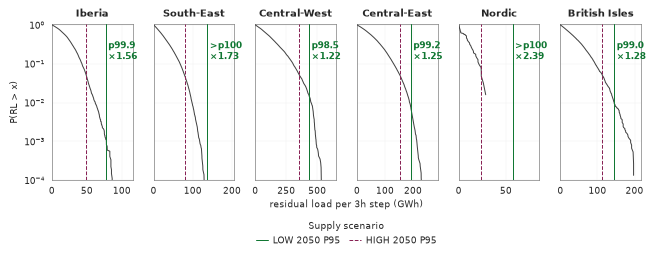

In [22]:
def figure_s27():
    fig, axes = plt.subplots(1, len(zones), figsize=(WIDTH, 48 * MM), sharey=True,
                             gridspec_kw={"wspace": 0.26})   # the right-hand labels need the gap
    for ax, zone in zip(axes, zones):
        values = high["cerra_deficit"].sel(zone=zone).values
        positive = np.sort(values[np.isfinite(values)])
        survival = 1.0 - np.arange(len(positive)) / len(positive)      # P(RL > x | RL > 0)
        thr_paper = float(zone_threshold.sel(zone=zone))
        thr_own = float(high["threshold"].sel(zone=zone))
        pctile = 100 * float((positive <= thr_paper).mean())

        ax.plot(positive, survival, color="0.25", lw=0.8, zorder=3)
        # LOW drawn first so it leads the legend, as it does in Figure 8. The labels are written out
        # here rather than taken from SCENARIO_LABELS, which is shared with Figure 8 and carries a
        # "(the paper)" parenthetical that belongs there and not on an axis this narrow.
        ax.axvline(thr_paper, color=SCENARIO_COLORS[0], ls="-", lw=0.8, zorder=4,
                   label="LOW 2050 P95")
        ax.axvline(thr_own, color=SCENARIO_COLORS[1], ls="--", lw=0.8, zorder=4,
                   label="HIGH 2050 P95")
        ax.set_yscale("log")
        ax.set_ylim(1e-4, 1.05)
        ax.set_xlim(0, max(thr_paper, thr_own) * 1.5)     # focus on the threshold region
        ax.set_title(ZONE_LABELS[zone], fontsize=FS["title"], fontweight="bold")
        ax.tick_params(labelsize=FS["tick"])
        ax.grid(True, which="major", color="0.93", lw=0.3)
        ax.set_axisbelow(True)
        # ">p100" where the paper's threshold sits beyond EVERY observed value -- South-East and
        # the Nordic, whose curves end short of the line. The test is on the values rather than on
        # the rounded percentile, which also reads 100.0 for a threshold merely close to the max.
        placement = ">p100" if thr_paper > positive[-1] else f"p{pctile:.1f}"
        # Parked at P = 0.4 beside the paper's threshold; no curve reaches that high there.
        ax.annotate(f"{placement}\n\u00d7{thr_paper / thr_own:.2f}",
                    xy=(thr_paper, 0.4), xytext=(2, 0), textcoords="offset points",
                    ha="left", va="top", fontsize=FS["tick"], fontweight="bold",
                    color=SCENARIO_COLORS[0])
        if zone == zones[0]:
            ax.set_ylabel("P(RL > x)", fontsize=FS["label"])

    fit_width(fig)
    fig.canvas.draw()
    renderer, inv = fig.canvas.get_renderer(), fig.transFigure.inverted()
    boxes = [a.get_tightbbox(renderer).transformed(inv) for a in axes]
    fig.text(0.5 * (axes[0].get_position().x0 + axes[-1].get_position().x1),
             min(b.y0 for b in boxes) - 3.0 / 72 / fig.get_figheight(),
             "residual load per 3h step (GWh)", ha="center", va="top", fontsize=FS["label"])
    handles, labels = axes[0].get_legend_handles_labels()
    legend_below(fig, list(axes), handles, labels, ncol=2, gap_pt=14.0,
                 title="Supply scenario", title_fontsize=FS["tick"])
    return fig


with publication_rc():
    fig = figure_s27()
    save(fig, "S27_threshold_placement", FIGS)
plt.show()

## 6 · S28: the deficit tail, every zone and every season

Figure 5b of the main text draws these curves for the two southern zones, in winter and summer. This
is the same quantity for **all six zones and all four seasons**, so the zones and the shoulder
seasons the main figure omits are on the record rather than asserted to be quiet.

> **Supplementary Figure 28 | Exceedance curves of the zonal residual load, for every balancing zone
> and every season.** Survival curves P(RL > x) of the zonal residual load: columns are the six
> balancing zones, rows the four meteorological seasons, on a logarithmic probability axis. Lines are
> the ensemble median across nine chains and the shading the inter-model interquartile range; colour
> denotes warming level. The dashed rule and the grey band mark the zone's CERRA p95 deficit
> threshold — the same threshold the event detector uses throughout. The annotation gives the factor
> by which the probability of exceeding that threshold changes between +1.5 °C and +3.0 °C, coloured
> by direction. Drawn by the same builder as Figure 5b, so the two differ only in which zones and
> seasons are selected.


  S28_tail_all_seasons         180.5 x  88.2 mm   panel 14.3 mm   pdf 267 kB  png 495 kB


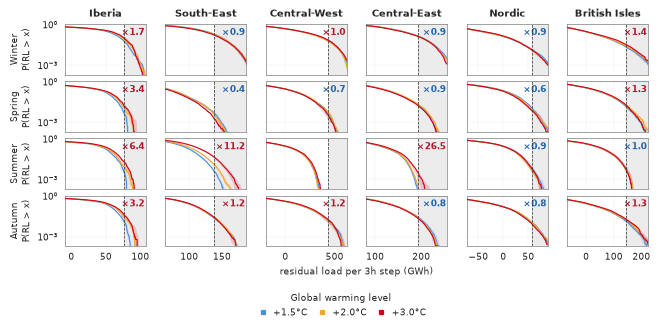

In [24]:
with publication_rc():
    fig = tail_exceedance_figure(
        seasons=SEASON_ORDER, residual_load_by_model=main["residual_load"],
        period_defs=period_defs, zone_threshold=zone_threshold,
        zone_season_hours=events_by_season,
        season_months=SEASON_MONTHS, duration_labels=DURATION_LABELS, style=STYLE, spread=SPREAD,
        # Survival grid only. The exceedance block below it is hard-coded to four axes and filled
        # class-major, so with four seasons it drew sub-daily four times and silently dropped the
        # multi-day class its caption claimed to show.
        duration_block=False, height_mm=92)
    save(fig, "S28_tail_all_seasons", FIGS)
plt.show()

## 7 · S29: the duration spectrum, zone by zone

Figure 5c/d sums the duration spectrum over all six zones. Split by zone it shows where the European
signal comes from: the rise in sub-daily events is almost entirely Iberia and the South-East, and
Iberia is the one zone whose severity peaks in the sub-daily bins.

> **Supplementary Figure 29 | Extreme events and their severity by duration, for each balancing
> zone.** **a**, Extreme events per year by event duration; **b**, their severity, the energy above
> the zone's CERRA p95 threshold, on the same duration axis. Columns are the six balancing zones, each
> on its own vertical scale. Lines are the ensemble median over nine chains and shading the
> interquartile range; colour denotes warming level. The dashed rule marks the 24 h boundary between
> the paper's two duration classes. Summed over zones within each chain, these are Figure 5c and d.


[cache] hit   note3_attenuation  (11 MB, 0s)
attenuation table + 55,914 per-event rows [0s]
median change in sub-daily events per year, by zone:
zone
British_Isles         1.00
Central_Eastern       0.25
Central_Western       0.45
Iberian_Peninsula    12.50
Nordic               -0.75
South_East            8.30
  S29_duration_spectrum_by_zone 179.8 x 120.8 mm   panel 42.4 mm   pdf 59 kB  png 766 kB


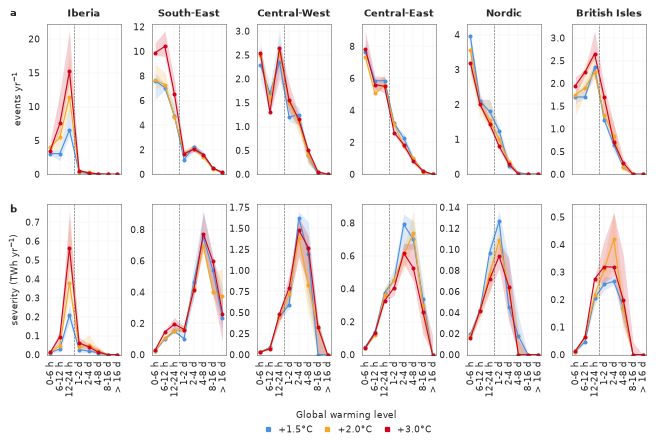

In [26]:
# ── S29: Figure 5c/d resolved by zone ──────────────────────────────────────────────────
# The per-event attenuation table, built here because this is now its first user; S33 reuses it.
started = time.perf_counter()
storage_attenuation, storage_events = cached(
    "note3_attenuation",
    lambda: compute_flexibility_attenuation_metrics(
        main["residual_load"], main["components"], main["threshold_by_model"], period_defs,
        models, zones, duration_bins=DURATION_BINS, method=EVENT_DETECTION, return_events=True),
    key=RUN_KEY, files=RUN_FILES)
print(f"attenuation table + {len(storage_events):,} per-event rows "
      f"[{time.perf_counter() - started:.0f}s]")

# The SAME per-event table as Figure 5 (`storage_events`, from compute_flexibility_attenuation_metrics
# with return_events=True, built above) and the same bins, with zone kept in the groupby.
DURATION_EDGES = [0, 6, 12, 24, 48, 96, 192, 384, 1e4]
DURATION_BIN_LABELS = ["0-6 h", "6-12 h", "12-24 h", "1-2 d", "2-4 d", "4-8 d", "8-16 d", "> 16 d"]


def spectrum_by_zone(value):
    rows = []
    for (model, period, zone), block in storage_events.groupby(["model", "period", "zone"]):
        for lo, hi, label in zip(DURATION_EDGES[:-1], DURATION_EDGES[1:], DURATION_BIN_LABELS):
            inside = block[(block.duration_h > lo) & (block.duration_h <= hi)]
            rows.append(dict(model=model, period=period, zone=zone, bin=label,
                             value=(len(inside) if value == "counts"
                                    else inside.sev_actual.sum() / 1e3) / 20.0))
    return pd.DataFrame(rows)


zone_spectrum = {"counts": spectrum_by_zone("counts"), "severity": spectrum_by_zone("severity")}

# The caption's claim: the Europe-wide sub-daily rise is carried by Iberia and the South-East.
_sub = zone_spectrum["counts"][zone_spectrum["counts"].bin.isin(DURATION_BIN_LABELS[:3])]
_per = _sub.groupby(["model", "period", "zone"])["value"].sum().unstack("period")
_dzone = (_per[WARMEST] - _per[REFERENCE]).groupby("zone").median()
print("median change in sub-daily events per year, by zone:"); print(_dzone.round(2).to_string())
_south = float(_dzone[["Iberian_Peninsula", "South_East"]].sum())
assert _south > 0.8 * float(_dzone.sum()), \
    f"Iberia + South-East no longer carry the sub-daily rise ({_south:.1f} of {float(_dzone.sum()):.1f})"


def figure_s29():
    fig, axes = plt.subplots(2, len(ZONE_ORDER), figsize=(WIDTH, 100 * MM), sharex=True,
                             gridspec_kw={"hspace": 0.20, "wspace": 0.42})
    x = np.arange(len(DURATION_BIN_LABELS))
    for r, (key, ylabel) in enumerate((("counts", "events yr$^{-1}$"),
                                      ("severity", "severity (TWh yr$^{-1}$)"))):
        table = zone_spectrum[key]
        for c, zone in enumerate(ZONE_ORDER):
            ax = axes[r, c]
            block = table[table.zone == zone]
            for period in period_names:
                wide = block[block.period == period].pivot(index="model", columns="bin",
                                                          values="value")[DURATION_BIN_LABELS]
                ax.fill_between(x, wide.quantile(0.25), wide.quantile(0.75),
                                color=STYLE.gwl_colors[period], alpha=0.18, lw=0)
                ax.plot(x, wide.median(), "o-", ms=2.2, lw=0.9, color=STYLE.gwl_colors[period])
            ax.axvline(2.5, color="0.4", ls="--", lw=0.5)
            ax.set_ylim(bottom=0)
            if r == 0:
                ax.set_title(ZONE_LABELS[zone], fontsize=FS["title"], fontweight="bold")
            if c == 0:
                ax.set_ylabel(ylabel, fontsize=FS["label"])
            ax.tick_params(labelsize=FS["tick"])
            ax.set_xticks(x)
            ax.set_xticklabels(DURATION_BIN_LABELS, rotation=90, fontsize=FS["tick"])
            ax.grid(True, color="0.93", lw=0.3)
            ax.set_axisbelow(True)
    fit_width(fig)
    legend_below(fig, list(axes[-1]), *gwl_handles(STYLE), ncol=3, title=GWL_TITLE)
    panel_letters(fig, [("a", axes[0, 0]), ("b", axes[1, 0])])
    return fig


with publication_rc():
    fig = figure_s29()
    save(fig, "S29_duration_spectrum_by_zone", FIGS)
plt.show()


## 8 · S30: the diurnal cycle and its drivers, zone by zone

Figure 6's second row is about Southern Europe: panel c pools Iberia and the South-East, and panel d
decomposes the drivers for those two zones so the row keeps one subject. This figure is that pair,
repeated for every zone.

It **replaces** the earlier northern-drivers figure. That one existed only because Figure 6d had
been cut to the south, and pairing each zone's drivers with its own diurnal profile supersedes it —
keeping both would print the four northern driver panels twice.

The two southern rows partly repeat Figure 6, and deliberately. Their **diurnal** panels are new,
because Figure 6c pools Iberia and the South-East and these show them apart; their **driver** panels
are the same two Figure 6d draws. That is the right trade for a reference figure a reader consults
one zone at a time.

The northern zones are not a null result — Central-East's evening peak moves as much as Iberia's —
but they move for different reasons and on a different seasonal cycle, which is exactly why mixing
them into a southern panel made that panel harder to read rather than more complete.

**How to read it.** The left column of each row counts exceedance timestep by timestep against the
zone's p95 threshold, with no event detector involved; y limits are per zone and the two seasons sit
on separate axes, because a shared limit would leave most of the figure blank. The right column
decomposes the change in residual load over both shaded windows of the row beside it — evening and
overnight together, everything but the midday PV hours — with season as a labelled position under
each stack. Winter and summer are the two seasons for which that window is defined. A positive
contribution deepens the deficit and a negative one eases it, the convention Figure 6d draws as
arrows in its gutter. Rows **a**–**d** are the two zones Figure 6 pools, drawn separately here.

> **Supplementary Figure 30 | Exceedance by hour of day and its driver decomposition, for each
> balancing zone.** **a**, **c**, **e**, **g**, **i**, **k**, Hours per year above the zone's p95
> threshold by hour of day, summer above winter, at each warming level; shaded bands give the
> interquartile range across nine chains and shaded vertical spans mark the evening and overnight
> windows, labelled in the top row. **b**, **d**, **f**, **h**, **j**, **l**, Contribution of each
> supply and demand driver to the change in residual load between +1.5 °C and +3.0 °C over those
> windows, as diverging stacked bars. Black diamonds give the net change with its interquartile
> range; hatching marks drivers on which fewer than six of nine chains agree.

deficit-window attribution [2s]
  S30_diurnal_and_drivers_by_zone 180.0 x 208.3 mm   panel  9.2 mm   pdf 123 kB  png 791 kB

Net deficit-window change, +1.5 -> +3.0 (GWh), median across chains (agreement in brackets):
  Iberia        DJF    +3.5 (8/9)   JJA    +6.8 (9/9)  <- also in Figure 6d
  South-East    DJF    -5.9 (9/9)   JJA   +14.0 (9/9)  <- also in Figure 6d
  Central-West  DJF    -5.1 (6/9)   JJA   +20.8 (8/9)
  Central-East  DJF    -2.3 (8/9)   JJA    +4.2 (9/9)
  Nordic        DJF    -2.5 (6/9)   JJA    -0.2 (6/9)
  British Isles DJF    +4.3 (5/9)   JJA    +6.4 (8/9)

JJA exceedance at the evening peak (18:00), hours per year, median across chains:
  Iberia        +1.5°C   1.5  +2.0°C   3.8  +3.0°C  10.8
  South-East    +1.5°C   3.9  +2.0°C  10.5  +3.0°C  31.1
  Central-West  +1.5°C   0.0  +2.0°C   0.0  +3.0°C   0.0
  Central-East  +1.5°C   0.3  +2.0°C   0.6  +3.0°C   5.1
  Nordic        +1.5°C   3.3  +2.0°C   2.5  +3.0°C   2.7
  British Isles +1.5°C   2.7  +2.0°C   2.2  +3

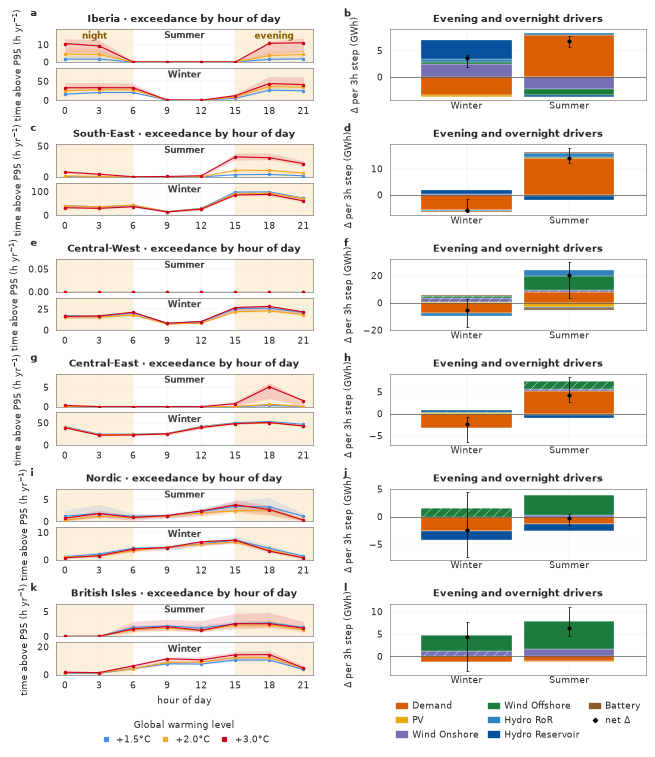

In [28]:
# -- S30: Figure 6's second row, one zone at a time -------------------------------------
# The same two panels Figure 6 pairs -- the diurnal exceedance profile and the driver
# decomposition over the deficit window -- drawn for every zone rather than the southern pair.
# This ABSORBS the old northern-drivers figure: that one existed only because Figure 6d was cut to
# the south, and pairing each zone's drivers with its own diurnal profile supersedes it. Keeping
# both would print the four northern driver panels twice.
started = time.perf_counter()
# `hours=DEFICIT_WINDOW_HOURS`, matching Figure 6d: these are the same construction, so a window
# that moved in one and not the other would make the two figures disagree about the same quantity.
evening_peak_components = compute_evening_peak_attribution(
    main["residual_load"], main["components"], period_defs, zones, SEASON_MAP,
    hours=DEFICIT_WINDOW_HOURS)
print(f"deficit-window attribution [{time.perf_counter() - started:.0f}s]")

SOUTHERN_ZONES = ["Iberian_Peninsula", "South_East"]
EVENING_SEASONS = ("DJF", "JJA")
EVENING_WINDOW, NIGHT_WINDOW = (15, 21.8), (-0.8, 6.0)


def figure_s30():
    """Six rows of (diurnal | drivers), one zone each, in the paper's zone order."""
    # 246 -> 198 mm. At 249 mm rendered, no caption length was legal: the ceiling is 225 mm
    # and that only with a legend under 50 words. 198 mm renders near 202 and clears the
    # 210 mm band a caption under 150 words buys.
    fig = plt.figure(figsize=(WIDTH, 198 * MM))
    # hspace separates the ZONE rows and is generous, because each row ends in the driver panel's
    # two-level x axis (season over zone) and the diurnal cell's "hour of day" label. wspace has to
    # clear the driver panel's y-label gutter, which is a fixed 12.4 mm.
    grid = gridspec.GridSpec(len(ZONE_ORDER), 2, hspace=0.62, wspace=0.30, figure=fig)

    lettered, first_row, last_djf = [], True, None
    for row, zone in enumerate(ZONE_ORDER):
        # The diurnal cell keeps Figure 6c's STACKED JJA-over-DJF axes rather than one shared pair.
        # Within a zone the two seasons differ by roughly 2.5x, and a shared axis flattens summer --
        # which is why Figure 6c stacks them in the first place. Across zones the span is larger
        # still (southern JJA reaches ~39 h/yr where the Nordic is near zero), so the y limits are
        # per zone as well: a common limit would leave four of the six rows blank.
        cell = gridspec.GridSpecFromSubplotSpec(2, 1, subplot_spec=grid[row, 0], hspace=0.18)
        ax_jja, last_djf = fig.add_subplot(cell[0]), fig.add_subplot(cell[1])
        zone_hours = hour_exceedance[hour_exceedance.zone == zone]
        panel_hour_of_day(
            ax_jja, last_djf, zone_hours, STYLE,
            evening=EVENING_WINDOW, night=NIGHT_WINDOW,
            # The window names label the shaded bands, which are the same bands in every row, so
            # only the top row carries them.
            evening_label="evening" if first_row else "",
            night_label="night" if first_row else "",
            # "hours above P95", the label Figure 6c uses, is 24 mm of type at 6.5 pt against a
            # ~15 mm axis here, so the two stacked labels ran into each other in all six rows and
            # three panel letters landed on top of them. The caption carries the full quantity.
            ylabel="time above P95 (h yr$^{-1}$)")
        ax_jja.set_title(f"{ZONE_LABELS[zone]} · exceedance by hour of day",
                         fontsize=FS["title"], fontweight="bold")
        # "hour of day" under the bottom row only: at 7.5 pt, one per row ran into the next
        # row's title in a figure already at its 210 mm height budget.
        if row < len(ZONE_ORDER) - 1:
            last_djf.set_xlabel("")

        ax_drivers = fig.add_subplot(grid[row, 1])
        panel_driver_attribution(
            ax_drivers,
            lambda z, season: attribution_change_by_model(
                evening_peak_components, z, season, REFERENCE, WARMEST, STYLE.drivers),
            list(EVENING_SEASONS), replace(STYLE, zones=[zone]),
            ylabel="Δ per 3h step (GWh)", show_sign_convention=False,
            # No arrow gutter to reserve (the sign convention is in the caption), and no zone name
            # under the stacks: the row's left title already names it.
            reserve_sign_gutter=False, show_zone_labels=False)
        # No zone name in this title: the zone already sits under the stacks, drawn by the panel's
        # own two-level x axis, and the diurnal panel beside it is titled with the zone as well.
        ax_drivers.set_title("Evening and overnight drivers", fontsize=FS["title"],
                             fontweight="bold")

        lettered += [ax_jja, ax_drivers]
        first_row = False

    fit_width(fig)
    gwl_h, gwl_l = gwl_handles(STYLE)
    drv_h, drv_l = driver_handles(STYLE)
    # One key per COLUMN, both under the last row: the warming levels belong to the diurnal curves
    # and the drivers to the stacks, and a single combined key would put eleven entries under a
    # figure whose two halves use them separately. The sign convention the driver panels would
    # normally carry in their gutter is in the caption instead — its two rotated labels do not fit
    # beside a 40 mm panel without running into each other.
    # Anchored on the DJF axis, not on the JJA one `lettered` holds: within a diurnal cell JJA is
    # the TOP of the two stacked axes, so a legend measured off it would land on the DJF axis below.
    legend_below(fig, last_djf, gwl_h, gwl_l, ncol=len(gwl_l), title=GWL_TITLE)
    legend_below(fig, lettered[-1], drv_h,
                 [DRIVER_DISPLAY.get(name, name) for name in drv_l], ncol=3)   # at 7 pt four columns ran 14 mm past the figure edge
    panel_letters(fig, list(zip("abcdefghijkl", lettered)))
    return fig


with publication_rc():
    fig = figure_s30()
    save(fig, "S30_diurnal_and_drivers_by_zone", FIGS)
plt.show()

# The figure's whole point is that no zone is left out, which is what the northern-drivers figure it
# replaces was for. Assert coverage rather than trusting the loop.
assert set(ZONE_ORDER) == set(zones), \
    f"S30 does not cover every zone: {sorted(set(zones) ^ set(ZONE_ORDER))}"
assert set(SOUTHERN_ZONES) <= set(ZONE_ORDER), "the zones Figure 6 draws are not all here"

print("\nNet deficit-window change, +1.5 -> +3.0 (GWh), median across chains "
      "(agreement in brackets):")
for _zone in ZONE_ORDER:
    _cells = []
    for _season in EVENING_SEASONS:
        _per_chain = attribution_change_by_model(evening_peak_components, _zone, _season,
                                                 REFERENCE, WARMEST, STYLE.drivers)["net"]
        _median = float(_per_chain.median())
        _agree = int((np.sign(_per_chain) == np.sign(_median)).sum())
        _cells.append(f"{_season} {_median:+7.1f} ({_agree}/{len(_per_chain)})")
    _mark = "  <- also in Figure 6d" if _zone in SOUTHERN_ZONES else ""
    print(f"  {ZONE_LABELS[_zone]:<14}" + "   ".join(_cells) + _mark)

print("\nJJA exceedance at the evening peak (18:00), hours per year, median across chains:")
for _zone in ZONE_ORDER:
    _at = hour_exceedance[(hour_exceedance.zone == _zone) & (hour_exceedance.season == "JJA")
                          & (hour_exceedance.hour == 18)]
    _by_period = _at.groupby("period")["hours_yr"].median()
    print(f"  {ZONE_LABELS[_zone]:<14}"
          + "  ".join(f"{p} {_by_period.get(p, 0.0):5.1f}" for p in period_names))


## 9 · S31: the multi-day regime

The main text's deep dive is sub-daily, because that is where the change is: Europe gains
**+19.7 sub-daily events per year** between +1.5 °C and +3.0 °C against **+0.85 multi-day ones**, a
factor of twenty-three. (Figure 5c bins individual events by their own length rather than by the
detector's duration class and gets +23.85 against +0.45 — a different count of the same asymmetry,
not a different result. Quote one table per sentence.) The multi-day regime is not therefore uninteresting — it is where the storage
fleet stops coping, and Figure 7 is about exactly that — but its *counts* are flat, and a main
figure whose headline is "almost nothing happens in total" earns its place better here.

Flat in total is not flat everywhere. The European count goes 19.6 → 20.4 events per year while the
Central-East loses 20 % of its multi-day events, the Nordic 15 %, and the British Isles gain 33 % —
a cancellation, not an absence. Panel **b** is where that cancellation is visible.

Built by **the same function as Figure 6**, called with the multi-day duration class, so the two
regimes are drawn by one builder and cannot drift apart. The differences are the ones the data
forces: no hour-of-day panel, since a multi-day event spans whole days and an hour-of-day profile of
one would be meaningless, which frees the whole bottom row for the driver decomposition; and its own
colour-bin edges in panel **b**, because the multi-day grid spans −0.80 to +0.70 events per year
against the sub-daily −0.90 to +7.90 and a shared ramp would put every multi-day cell in the neutral
class.

**Why panel c decomposes the seasonal mean, and not the events themselves.** The obvious
alternative is to ask how the events change — the mean over multi-day event timesteps at +3.0 °C
against the same at +1.5 °C. Measured, that quantity is empty: it sits between −1.4 and +0.2 GWh per
3 h in every zone and season, against 1.8 to 13.0 for the seasonal change, and in the British Isles
and the South-East the two even carry opposite signs. The flatness is a selection effect rather than
a result. An event is *defined* as exceeding a fixed absolute threshold, so conditioning on being an
event pins the residual load near that threshold in both climates; a panel built on it would be
measuring the threshold. Warming changes how often the background crosses the line, not what the
system looks like once it has, and the seasonal mean is the background that moves. There is also no
diurnal window to condition on the way Figure 6d does: an event lasting more than 24 h covers every
hour by construction, and the observed spread across the eight 3-hourly slots is 0.9 to 4.5
percentage points against a uniform 12.5 %. For multi-day events the season *is* the conditioned
background.

> **Supplementary Figure 31 | Multi-day extreme events: frequency, seasonal decomposition and
> drivers.**
> **a**, Multi-day (> 24 h) extreme events per year by zone and warming level, as box plots over the
> nine chains; the annotation is the median of each chain's own change from +1.5 °C to +3.0 °C, not
> the ratio of the two medians. **b**, The change in events yr⁻¹ between those levels, by season
> and zone, in discrete colour classes set for this duration class alone; hatching and the *none*
> label are as in Figure 6b. **c**, Contribution of each driver to the change in the seasonal-mean
> residual load between the two levels, all six zones and all four seasons, as diverging stacked
> bars with the net change as a black diamond and its interquartile range; hatching marks drivers on which
> fewer than six of nine chains agree.

  S31_multi_day_regime         179.9 x 134.0 mm   panel 37.1 mm   pdf 84 kB  png 476 kB

S31c, net change in the seasonal-mean residual load (GWh), median across chains:
  DJF  Iberia  +1.8  South-East  -6.0  Central-West  -2.0  Central-East  -1.8  Nordic  -2.6  British Isles  +4.0
  MAM  Iberia  +0.8  South-East  -4.6  Central-West  -6.5  Central-East  -2.0  Nordic  +0.2  British Isles  +6.2
  JJA  Iberia  +7.4  South-East +14.0  Central-West +18.5  Central-East  +3.7  Nordic  -0.3  British Isles  +6.4
  SON  Iberia  +4.9  South-East  +0.5  Central-West  -3.5  Central-East  -2.5  Nordic  -1.3  British Isles  +4.0
Summer deepens the deficit in 5 of 6 zones (all but the Nordic, -0.3 GWh).

Europe-wide change in events/yr: sub_daily +19.70  multi_day +0.85
Multi-day, Europe total: 19.6 -> 20.4 events/yr
Paired change in multi-day events per zone (%):
  Iberia           +50
  South-East        +6
  Central-West      +3
  Central-East     -20
  Nordic           -15
  British Isles    +33


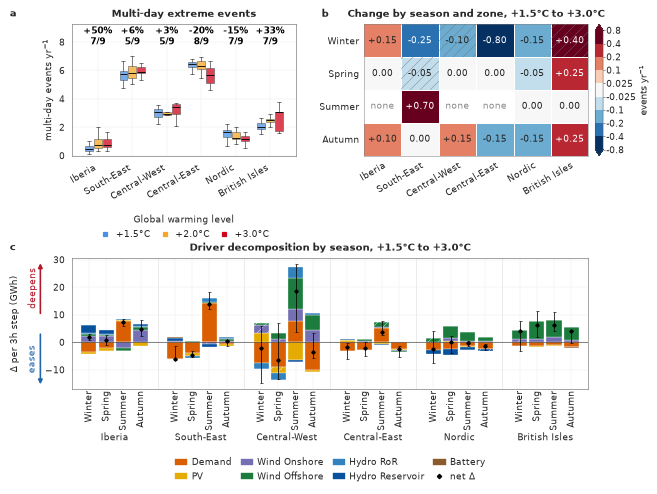

In [30]:
# -- S31: the multi-day regime, by the SAME builder as Figure 6 --------------------------
# `regime_figure` lives in plotting_publication precisely so this call and the main notebook's
# sub-daily one are the same code. A local copy here is a copy that drifts from the figure it has
# to stay comparable with.
S31_TITLES = {
    "a": "Multi-day extreme events",
    # Shorter than Figure 6b's: this heatmap's class labels are wider (-0.025), and at 8 pt the
    # full title ran onto the panel letter.
    "b": f"Change by season and zone, {REFERENCE} to {WARMEST}",
    "c": f"Driver decomposition by season, {REFERENCE} to {WARMEST}",
}


def figure_s31():
    return regime_figure(
        "multi_day",
        events_annual=events_annual, events_by_season=events_by_season, style=STYLE,
        titles=S31_TITLES, season_bins=SEASON_COUNT_BINS_MULTI_DAY, seasons=SEASON_ORDER,
        # All four seasons, and the seasonal column template the multi-day table uses -- this is
        # the seasonal-MEAN attribution, not the deficit-window one S30 draws.
        attribution=lambda zone, season: attribution_change_by_model(
            multi_day_events, zone, season, REFERENCE, WARMEST, STYLE.drivers,
            column_template="{season}_{driver}", net_column="{season}_RL"),
        driver_seasons=SEASON_ORDER,
        # No diurnal table: a multi-day event spans whole days, so an hour-of-day profile of one
        # would be meaningless. `regime_figure` gives the driver panel the full bottom row instead.
        diurnal=None,
        driver_display=DRIVER_DISPLAY, letters="abc")


with publication_rc():
    fig = figure_s31()
    save(fig, "S31_multi_day_regime", FIGS)
plt.show()

# Panel c's caption is a claim about the net change, so it is measured rather than asserted by eye.
_nets = {}
for _season in SEASON_ORDER:
    for _zone in zones:
        _pc = attribution_change_by_model(multi_day_events, _zone, _season, REFERENCE, WARMEST,
                                          STYLE.drivers, column_template="{season}_{driver}",
                                          net_column="{season}_RL")
        _nets[(_season, _zone)] = float(_pc["net"].median())
print("\nS31c, net change in the seasonal-mean residual load (GWh), median across chains:")
for _season in SEASON_ORDER:
    print(f"  {_season}  " + "  ".join(f"{ZONE_LABELS[z]} {_nets[(_season, z)]:+5.1f}"
                                       for z in zones))
_jja_up = [ZONE_LABELS[z] for z in zones if _nets[("JJA", z)] > 0]
print(f"Summer deepens the deficit in {len(_jja_up)} of {len(zones)} zones "
      f"(all but the Nordic, {_nets[('JJA', 'Nordic')]:+.1f} GWh).")

# The caption states the two magnitudes and the zonal cancellation; both are asserted, because a
# caption number that drifts from the table is the failure this notebook exists to prevent.
_by_class = (events_annual.groupby(["model", "period", "duration_class"])["freq_per_year"]
             .sum().groupby(["period", "duration_class"]).median())
_deltas = {dc: _by_class[(WARMEST, dc)] - _by_class[(REFERENCE, dc)] for dc in DURATION_BINS}
print(f"\nEurope-wide change in events/yr: "
      + "  ".join(f"{dc} {_deltas[dc]:+.2f}" for dc in DURATION_BINS))
assert _deltas["sub_daily"] > 10 * abs(_deltas["multi_day"]), (
    "the caption's 'sub-daily adds fifty times the multi-day' claim no longer holds by even a "
    f"factor of ten: {_deltas}")
_europe = _by_class[(REFERENCE, "multi_day")], _by_class[(WARMEST, "multi_day")]
print(f"Multi-day, Europe total: {_europe[0]:.1f} -> {_europe[1]:.1f} events/yr")

_zonal = (events_annual[events_annual.duration_class == "multi_day"]
          .pivot_table(index=["zone", "model"], columns="period", values="freq_per_year"))
_paired = ((_zonal[WARMEST] / _zonal[REFERENCE] - 1) * 100).groupby("zone").median()
print("Paired change in multi-day events per zone (%):")
for _zone in zones:
    print(f"  {ZONE_LABELS[_zone]:<14}{_paired.get(_zone, float('nan')):+6.0f}")
assert (_paired < 0).any() and (_paired > 0).any(), \
    "the caption calls the flat European total a cancellation, but no zone now moves the other way"


## 10 · S32: why Iberian attenuation degrades under warming

Iberia is the zone where storage stops coping: the share of extreme-event severity its fleet balances
falls with warming while every other zone holds roughly steady. The reason is not that the fleet
shrinks — the build-out is fixed — but that the water it runs on arrives differently.

The figure puts the two parts of that argument together: **a** the balanced share falling, and **b**
the resource behind it. The remaining panels of the earlier version of this figure are dropped: the
all-zone balanced shares are Figure 7a, and the balanced-share-against-event-size panel answered a
question about event magnitude rather than about the resource.

**How each panel is computed.** **a** uses a two-player Shapley split of extreme-event severity into
a reservoir and a battery contribution, so the two segments sum exactly to the combined attenuation.
**b** is the reservoir *resource*, not the decision: inflow is the water the climate delivers to the
Iberian fleet, dispatch is what the optimiser then releases. Both are summed over each chain's own
20-year window and divided by it, so they are per-year quantities on a common basis, and both are
shown at +3.0 °C as the change from +1.5 °C.

> **Supplementary Figure 32 | Why Iberian attenuation degrades under warming.** **a**, Share of
> extreme-event severity balanced by storage in Iberia, split into reservoir and battery
> contributions by a two-player Shapley decomposition, at each warming level and for both duration
> classes; the two segments sum exactly to the combined attenuation. **b**, Iberian reservoir inflow
> and dispatch at **+3.0 °C**, as the percentage change from +1.5 °C, by season — the resource the
> climate delivers and what the optimiser releases from it. Bars are ensemble medians across nine
> chains; error bars in **b** give the interquartile range. Winter and spring lose the inflow that
> summer dispatch was drawing on, which is why the balanced share falls.


In [32]:
# -- S32: the Iberian attenuation mechanism ----------------------------------------------
# `return_events` gives the per-event rows the summary averages away. They are what the mechanism
# question needs: an aggregate cannot distinguish "storage degraded" from "the events got bigger",
# and only individual events can be conditioned on their own counterfactual severity.
# `storage_attenuation` / `storage_events` are built in the S30 cell above (cached).

GWL_SUBLABELS = [p.strip("+").replace("°C", "").strip() for p in period_names]
MECHANISM_CONTROL = "Central_Eastern"


def paired_share_change(duration_class, zone, column=None):
    """Each chain's own +1.5 to +3.0 change in absorbed share, then the median. (median, n_falling)"""
    rows = storage_attenuation[(storage_attenuation.duration_class == duration_class)
                               & (storage_attenuation.zone == zone)]
    if column is None:
        rows = rows.assign(value=rows["reservoir_attenuation_share_pct"]
                           + rows["battery_attenuation_share_pct"])
    else:
        rows = rows.assign(value=rows[column])
    levels = {p: rows[rows.period == p].set_index("model")["value"] for p in (REFERENCE, WARMEST)}
    shared = levels[REFERENCE].index.intersection(levels[WARMEST].index)
    change = levels[WARMEST].loc[shared] - levels[REFERENCE].loc[shared]
    return float(change.median()), int((change < 0).sum()), len(shared)


def panel_iberia_components(ax, zone):
    """Iberia's two Shapley shares at the three warming levels, sub-daily and multi-day side by side."""
    rows = storage_attenuation[storage_attenuation.zone == zone]
    width = 0.80 / len(period_names)
    for i, duration_class in enumerate(DURATION_BINS):
        for k, period in enumerate(period_names):
            cell = rows[(rows.duration_class == duration_class) & (rows.period == period)]
            bottom = 0.0
            for column, _label, color in STORAGE_PARTS:
                value = cell[column].median()
                ax.bar(i + (k - (len(period_names) - 1) / 2) * width, value, width * 0.88,
                       bottom=bottom, color=color, edgecolor="white", linewidth=0.4, zorder=2)
                bottom += value
        if i:
            ax.axvline(i - 0.5, color="0.85", lw=0.4, zorder=0)
    ax.set_ylim(0, 105)
    ax.set_xlim(-0.5, len(DURATION_BINS) - 0.5)
    ax.set_ylabel("share of severity\nbalanced by storage (%)", fontsize=FS["label"])
    ax.set_xticks([i + (k - (len(period_names) - 1) / 2) * width
                   for i in range(len(DURATION_BINS)) for k in range(len(period_names))])
    ax.set_xticklabels(GWL_SUBLABELS * len(DURATION_BINS), fontsize=FS["tick"])
    ax.tick_params(axis="x", length=0, pad=1.0)
    ax.tick_params(axis="y", labelsize=FS["tick"])
    for i, duration_class in enumerate(DURATION_BINS):
        ax.annotate(DURATION_TITLES[duration_class], xy=(i, 0), xycoords=("data", "axes fraction"),
                    xytext=(0, -11.0), textcoords="offset points", ha="center", va="top",
                    fontsize=FS["tick"], annotation_clip=False)



# ── The resource behind the falling absorbed share ──────────────────────────────────────
# Inflow from the c2e cache inflow from the c2e cache (country-level, the only place it exists)
# (country-level, the only place it exists) and dispatch from the zonal components. Summed over each
# chain's OWN window and divided by its length, so the two are per-year quantities that a chain with
# a longer record cannot dominate.
IBERIA = "Iberian_Peninsula"
_inflow = xr.open_dataarray(PATH_GWL / "c2e_cache" / f"c2e_hydro_inflow_{CLIMATE_SCENARIO}.nc")
_iberian = [c for c in REALTIME_BALANCING_ZONES[IBERIA]
            if c in {str(x) for x in _inflow["country"].values}]
print(f"Iberian countries with a reservoir fleet in the inflow cache: {_iberian}")

rows = []
for model in models:
    windows = resolve_model_periods(period_defs, model)
    dispatch_all = main["components"][model]["reservoir_dispatch_gwh"].sel(zone=IBERIA)
    inflow_all = _inflow.sel(model=model, country=_iberian).sum("country")
    for period, window in windows.items():
        if window is None:
            continue
        for name, series in (("inflow", inflow_all), ("dispatch", dispatch_all)):
            block = series.sel(time=slice(*window))
            months = pd.DatetimeIndex(block["time"].values).month
            years = len(set(pd.DatetimeIndex(block["time"].values).year))
            for season, season_months in SEASON_MONTHS.items():
                total = float(block.values[np.isin(months, season_months)].sum())
                rows.append(dict(model=model, period=period, season=season,
                                 quantity=name, per_year=total / years))
iberia_hydro = pd.DataFrame(rows)

_wide = iberia_hydro.pivot_table(index=["model", "season", "quantity"], columns="period",
                                 values="per_year")
iberia_change = ((_wide[WARMEST] - _wide[REFERENCE]) / _wide[REFERENCE] * 100).rename("pct")
print(f"\nIberian reservoir change, {REFERENCE} to {WARMEST} (%, median across chains):")
for _season in SEASON_ORDER:
    _line = "  ".join(
        f"{_q} {iberia_change.xs((_season, _q), level=('season', 'quantity')).median():+6.1f}%"
        for _q in ("inflow", "dispatch"))
    print(f"  {_season}  {_line}")

Iberian countries with a reservoir fleet in the inflow cache: ['ES', 'PT']

Iberian reservoir change, +1.5°C to +3.0°C (%, median across chains):
  DJF  inflow  -14.8%  dispatch  -19.3%
  MAM  inflow  -19.6%  dispatch  -29.0%
  JJA  inflow  -30.3%  dispatch   +4.3%
  SON  inflow  -21.0%  dispatch  -13.1%


  S32_iberia_attenuation       179.7 x  71.8 mm   panel 53.0 mm   pdf 99 kB  png 143 kB


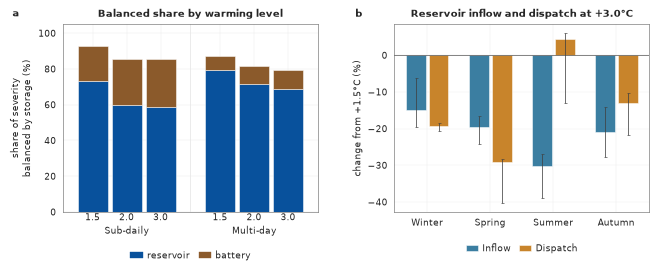

In [33]:
def figure_s32():
    """a, the absorbed share falling; b, the resource behind it."""
    fig = plt.figure(figsize=(WIDTH, 58 * MM))
    grid = gridspec.GridSpec(1, 2, wspace=0.30, figure=fig)

    ax_a = fig.add_subplot(grid[0, 0])
    panel_iberia_components(ax_a, IBERIA)
    ax_a.set_title("Balanced share by warming level", fontsize=FS["title"], fontweight="bold")

    # b -- the resource. Inflow and dispatch as a percentage change from the reference level, so
    # two quantities of very different absolute size (a reservoir releases far less than the basin
    # delivers) can share one axis.
    ax_b = fig.add_subplot(grid[0, 1])
    width = 0.36
    for k, (quantity, color) in enumerate((("inflow", "#3B7EA1"), ("dispatch", "#C8842B"))):
        offsets, mids, los, his = [], [], [], []
        for i, season in enumerate(SEASON_ORDER):
            values = iberia_change.xs((season, quantity), level=("season", "quantity")).values
            low, high = model_spread_bounds(values, STYLE.spread, axis=0)
            offsets.append(i + (k - 0.5) * width)
            mids.append(float(np.median(values)))
            los.append(float(np.median(values)) - low)
            his.append(high - float(np.median(values)))
        ax_b.bar(offsets, mids, width * 0.88, color=color, edgecolor="white", linewidth=0.4,
                 zorder=2, label=quantity.capitalize())
        ax_b.errorbar(offsets, mids, yerr=[los, his], fmt="none", ecolor="0.25", elinewidth=0.6,
                      capsize=1.2, capthick=0.5, zorder=4)
    ax_b.axhline(0, color="0.25", lw=0.5, zorder=3)
    ax_b.set_xticks(range(len(SEASON_ORDER)))
    ax_b.set_xticklabels([season_label(s) for s in SEASON_ORDER], fontsize=FS["tick"])
    ax_b.set_ylabel(f"change from {REFERENCE} (%)", fontsize=FS["label"])
    # The title carries the level being shown and the y label the baseline it is measured from,
    # so the panel states the comparison without the caption.
    ax_b.set_title(f"Reservoir inflow and dispatch at {WARMEST}", fontsize=FS["title"], fontweight="bold")
    ax_b.tick_params(labelsize=FS["tick"])
    ax_b.grid(True, axis="y", color="0.93", lw=0.3)
    ax_b.set_axisbelow(True)
    fit_width(fig)
    legend_below(fig, [ax_a], *storage_handles(STYLE), ncol=2)
    # Under the panel, not inside it: at 7 pt the inside key sat on spring's dispatch whisker.
    legend_below(fig, [ax_b], *ax_b.get_legend_handles_labels(), ncol=2)
    panel_letters(fig, [("a", ax_a), ("b", ax_b)])
    return fig


with publication_rc():
    fig = figure_s32()
    save(fig, "S32_iberia_attenuation", FIGS)
plt.show()


## 11 · S33: what survives the HIGH/2050 build-out

Figure 8 shows that the larger build-out removes almost all of the deficit but says nothing about
what is left. This figure is that remainder, scored on the **same absolute CERRA p95 threshold as
LOW/2050** so the two build-outs are judged by one yardstick — re-calibrating on HIGH would move the
goalposts by exactly the quantity being measured, and Supplementary Fig. S27 shows how far: HIGH's
own p95 is 1.22 to 2.39 times lower in every zone.

**What survives is a winter problem, and what drives it is wind.** Summer is empty in every zone at
every warming level; 5.1 of the 5.7 remaining sub-daily events per year are winter ones, in
Central-East and Central-West above all. During those events onshore and offshore wind together
fall short by 643 GWh per 3h step in Central-West and 199 in Central-East, against 66 and 30 for demand
— an order of magnitude apart. **These are wind droughts.**

**Why the reference is the same hour of a typical winter, and not the evening.** An earlier version
of this figure referenced the evening window, on the grounds that most winter exceedance *hours*
fall in it. Measured on the events themselves that does not hold: they run 9 to 12 hours — three or
four timesteps — and only 46 to 64 % of their timesteps fall in 15–21 h, the rest running on into
the night, where the residual load is naturally *lower* than in the evening. An evening reference
would over-correct those steps. Matching each event timestep to the season mean **for its own hour**
removes the diurnal cycle exactly however the event is spread, and makes the split additive:
*total = diurnal position + weather*. Panels **c** and **d** are the last term and the total, so the
gap between them is the diurnal contribution: 2 % of the anomaly in the British Isles, 5 % in
Central-East, 10 % in Central-West, but **36 % in Iberia** — the one zone where when an event
happens matters nearly as much as what the weather is doing.

One caveat the figure does not show and the text must carry: the summer residual load still rises
with warming under HIGH, more than the winter one in every zone that retains events. What the
build-out removes is not the summer signal but its ability to clear the threshold.

**What the bars are.** Every value is an anomaly in a **mean**, not a total over a period: each bar
is a difference of mean 3-hourly residual load in GWh per 3h step, so a bar at 600 means the system
ran that much further into deficit in every event timestep, not that 600 GWh accumulated. Zones are
not normalised, so heights are comparable between them — Central-West's events really are several
times larger than Iberia's. Panels **c** and **d** difference the same quantity, the mean over an
event's timesteps, against two references: **c** against the winter mean for each timestep's own
hour of day, which removes the diurnal cycle exactly, and **d** against the plain winter mean. The
two differ by the diurnal-position term, so **d** − **c** is what an event owes to the hours it
falls in. South-East rests on five of the nine chains (0.05 events per year, 41 timesteps) where
every other zone rests on nine.

> **Supplementary Figure 33 | Extreme events that survive the HIGH/2050 build-out, scored on the
> LOW/2050 threshold.** **a**, Sub-daily (≤ 24 h) events per year by balancing zone, one sub-axis
> per season, one bar per warming level; ensemble median over nine chains. The four seasons share
> one vertical scale. Zones with no events of that class in that season, in any chain at any level,
> are labelled rather than left blank. **b**, The same for multi-day (> 24 h) events, on their own
> shared scale — they are about five times rarer. **c**, **d**, What is anomalous during a winter
> event at +3.0 °C, per driver, for every zone retaining a winter event; **c** measured against the
> winter mean for the event's own hour of day, **d** against the plain winter mean. The difference
> between them is what an event owes to the hours of the day it falls in. Black diamonds give the net with its interquartile range;
> hatching marks drivers on which fewer than six of nine chains agree; a positive contribution
> deepens the deficit.

In [35]:
# -- S33: the HIGH/2050 build-out, scored on the LOW/2050 threshold ----------------------
# `high` is already loaded above for S27. It carries HIGH's OWN p95; overriding the two threshold
# keys re-scores it on the paper's LOW level, which is the whole mechanism -- the threshold reaches
# the detector in exactly one place, as a scalar per (model, zone). Same idiom as remove_batteries,
# and no second copy of nine chains in memory.
started = time.perf_counter()
high_low_threshold = {**high, "threshold": zone_threshold,
                      "threshold_by_model": {m: zone_threshold for m in high["models"]}}
assert high_low_threshold["threshold"] is zone_threshold, \
    "S33 is not being scored on the paper's threshold"

events_annual_high, events_by_season_high = event_tables(high_low_threshold, period_defs)
print(f"HIGH tables scored on the LOW threshold [{time.perf_counter() - started:.0f}s]")

# The zones panels c and d draw: EVERY zone that still has a winter event, of either duration
# class, at any warming level. Derived rather than typed and with no arbitrary floor, so the panels
# cover exactly where events occur and the figure cannot come to draw a different set than the
# caption describes. Panels a and b keep all six zones, because a zone with none is informative.
_winter = events_by_season_high[events_by_season_high.season == "DJF"]
_by_zone = _winter.groupby(["zone", "duration_class", "period"])["freq_per_year"].median()
SURVIVOR_ZONES = [z for z in zones
                  if any(float(_by_zone.get((z, d, p), 0.0) or 0.0) > 0
                         for d in DURATION_BINS for p in period_names)]
_absent = [ZONE_LABELS[z] for z in zones if z not in SURVIVOR_ZONES]
print(f"zones with winter events: {[ZONE_LABELS[z] for z in SURVIVOR_ZONES]}"
      f"   (none in: {_absent or 'nowhere'})")
assert SURVIVOR_ZONES, "no zone retains a winter event; panels c and d would be empty"

# ── Panels c and d: what is anomalous DURING an event, with time of day controlled for ───
# The reference matters and the two obvious ones are both wrong. Against the plain season mean, the
# answer mixes "the weather was anomalous" with "this happened in the evening, when the residual
# load is higher anyway". Against the evening window, it over-corrects: MEASURED below, these
# events run 9-12 h and only about half their timesteps fall in 15-21 h, the rest running on into
# the night, where the residual load is naturally LOWER than in the evening.
#
# So the reference is the season mean FOR THAT HOUR OF DAY, which removes the diurnal cycle exactly
# however an event's steps are spread. The split is then additive, per chain:
#     total anomaly  =  diurnal position  +  weather anomaly
event_anomaly_high = event_anomaly_vs_hourly_climatology(
    high["residual_load"], high["components"], high_low_threshold["threshold_by_model"],
    period_defs, zones, SEASON_MAP, method=EVENT_DETECTION, max_duration_h=24.0)
print(f"event anomaly table: {len(event_anomaly_high)} rows "
      f"[{time.perf_counter() - started:.0f}s]")


def event_anomaly(block, zone, season, *, period=None):
    """One row per chain, driver columns plus `net`, for `panel_driver_attribution`.

    `block` selects a term of the split: "weather" is the event against the hour-matched
    climatology, "total" against the plain season mean, "diurnal" the difference between them.
    Signs are already the shared convention -- demand +, generation and storage - -- so a positive
    contribution deepens the deficit.
    """
    prefix = {"weather": "", "total": "TOT_", "diurnal": "DIU_"}[block]
    rows = event_anomaly_high[(event_anomaly_high.zone == zone)
                              & (event_anomaly_high.season == season)
                              & (event_anomaly_high.period == (period or WARMEST))
                              ].set_index("model")
    out = pd.DataFrame({driver: rows[f"{prefix}{driver}"] for driver in STYLE.drivers})
    out["net"] = rows[f"{prefix}net"]
    return out


# ── The invariants ──────────────────────────────────────────────────────────────────────
# 1. The premise of the figure, and the claim Figure 8 makes.
_europe = lambda t: float(t[t.duration_class == "sub_daily"].groupby(
    ["model", "period"])["freq_per_year"].sum().groupby("period").median().get(WARMEST, 0.0))
_low_total, _high_total = _europe(events_annual), _europe(events_annual_high)
print(f"\nEurope-wide sub-daily events per year at {WARMEST}: "
      f"LOW {_low_total:.1f}  HIGH {_high_total:.1f}  ({100 * _high_total / _low_total:.0f} %)")
assert _high_total < 0.2 * _low_total, \
    f"HIGH no longer removes most of the deficit: {_high_total:.1f} against {_low_total:.1f}"

# 2. The invariant the LOW tables carry, re-checked on HIGH.
_a = events_annual_high.set_index(["model", "period", "zone", "duration_class"])["freq_per_year"]
_s = events_by_season_high.groupby(["model", "period", "zone", "duration_class"])["freq_per_year"].sum()
assert np.allclose(_s.sort_index().values,
                   _a.sort_index().reindex(_s.sort_index().index).values), \
    "the four HIGH seasonal counts no longer sum to the HIGH annual count"

# 3. Summer is empty. The caption says so and it is the sharpest thing this figure states.
_by_season = events_by_season_high.groupby(
    ["duration_class", "season", "zone", "period"])["freq_per_year"].median()
_jja = [float(_by_season.get(("sub_daily", "JJA", z, p), 0.0) or 0.0)
        for z in zones for p in period_names]
assert max(_jja) <= 1e-9, f"HIGH now has summer sub-daily events: max {max(_jja):.3f} per year"

# 4. The split must be exact PER CHAIN. (It is not exact on the medians the panels draw, because a
#    median is not additive -- a property of the estimator, not a fault in the decomposition -- so
#    the check is made where the identity actually holds.)
_split = event_anomaly_high[event_anomaly_high.season == "DJF"].dropna(subset=["net"])
assert np.allclose(_split["net"] + _split["DIU_net"], _split["TOT_net"], atol=1e-6), \
    "the weather and diurnal terms do not sum to the total anomaly; the climatology is misaligned"

print(f"\nSub-daily events per year under HIGH at {WARMEST}, by season:")
print(f"  {'zone':<15}" + "".join(f"{s:>8}" for s in SEASON_ORDER) + f"{'total':>9}")
for _zone in zones:
    _v = [float(_by_season.get(("sub_daily", s, _zone, WARMEST), 0.0) or 0.0) for s in SEASON_ORDER]
    print(f"  {ZONE_LABELS[_zone]:<15}" + "".join(f"{x:>8.2f}" for x in _v) + f"{sum(_v):>9.2f}")

# 5. The measurement the reference choice rests on: the events are NOT confined to the evening, so
#    an evening-window reference would over-correct the steps that are not. A zone resting on two
#    chains is also visible here -- the anomaly is NaN for a chain with no event, drawn as a gap.
_w = event_anomaly_high[(event_anomaly_high.season == "DJF")
                        & (event_anomaly_high.period == WARMEST)]
print(f"\nWinter events at {WARMEST}: how confined to the evening window, and on what sample:")
print(f"  {'zone':<15}{'in 15-21 h':>12}{'chains':>8}{'steps':>8}")
for _zone in SURVIVOR_ZONES:
    _rows = _w[_w.zone == _zone]
    print(f"  {ZONE_LABELS[_zone]:<15}{100 * float(_rows['evening_share'].mean()):>11.0f} %"
          f"{int(_rows['net'].notna().sum()):>8}{int(_rows['n_steps'].sum()):>8}")
_share = float(_w[_w.zone.isin(SURVIVOR_ZONES)]["evening_share"].mean())
assert _share < 0.8, (
    f"event timesteps are now {100 * _share:.0f} % evening; if they were essentially all evening, "
    "an evening-window reference would be as good as the hour-matched one and simpler")

HIGH tables scored on the LOW threshold [3s]
zones with winter events: ['Iberia', 'South-East', 'Central-West', 'Central-East', 'British Isles']   (none in: ['Nordic'])
event anomaly table: 648 rows [13s]

Europe-wide sub-daily events per year at +3.0°C: LOW 93.5  HIGH 5.7  (6 %)

Sub-daily events per year under HIGH at +3.0°C, by season:
  zone                DJF     MAM     JJA     SON    total
  Iberia             0.25    0.00    0.00    0.00     0.25
  South-East         0.05    0.00    0.00    0.00     0.05
  Central-West       1.55    0.00    0.00    0.20     1.75
  Central-East       1.85    0.10    0.00    0.10     2.05
  Nordic             0.00    0.00    0.00    0.00     0.00
  British Isles      0.55    0.20    0.00    0.25     1.00

Winter events at +3.0°C: how confined to the evening window, and on what sample:
  zone             in 15-21 h  chains   steps
  Iberia                  46 %       9     182
  South-East              82 %       5      41
  Central-West          

  S33_high_buildout_survivors  179.6 x 175.7 mm   panel 24.7 mm   pdf 100 kB  png 550 kB

What an event is at +3.0°C (GWh per 3 h), median across chains:
  zone              weather   diurnal     total  diurnal %  chains   steps
  Iberia              100.9      56.2     157.2        36 %       9     182
  South-East          135.3      18.8     153.0        12 %       5      41
  Central-West        648.7      71.3     717.2        10 %       9    1265
  Central-East        222.4      12.3     234.6         5 %       9    1046
  British Isles       322.8       8.3     335.7         2 %       9     338
  Central-West: wind 643 against the next largest Demand 66 GWh per 3 h
  Central-East: wind 199 against the next largest Demand 30 GWh per 3 h


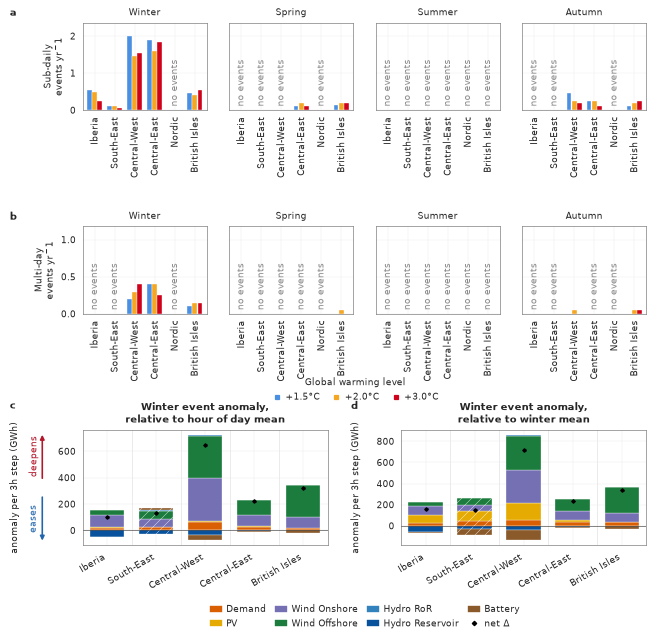

In [36]:
# Both panels show the SAME quantity -- the mean over an event's timesteps -- and differ only in
# what it is measured against, so the titles name the two references. "Time of day removed" and
# "time of day included" named the OPERATION instead, which leaves a reader with no idea what the
# anomaly is relative to. Both references are winter; c additionally matches each timestep's hour,
# so d - c is still the diurnal term.
# Two lines: at 8 pt each title is wider than its panel and they ran into one another.
S33_TITLES = {"c": "Winter event anomaly,\nrelative to hour of day mean",
              "d": "Winter event anomaly,\nrelative to winter mean"}


def figure_s33():
    """Where the survivors are (a, b), and what drives them at two different conditionings (c, d).

    Counts as LEVELS rather than the change Figure 6 plots: under HIGH a change grid would be
    almost entirely "none", and the question is where the survivors ARE.
    """
    # Taller than the panels need, and a wider inter-row gap than they need: the warming-level key
    # goes in the band between row b and the bottom row, which at hspace 0.78 is about 5 mm --
    # barely more than row b's rotated zone labels and the bottom row's titles already claim.
    fig = plt.figure(figsize=(WIDTH, 168 * MM))
    # The bottom row takes a larger share as well as the figure being taller: panel c's two
    # sign-convention labels run the full height of its axes and MEET at the zero line when that
    # row drops below ~30 mm, which is what paying for the wider gap out of the rows did.
    grid = gridspec.GridSpec(3, 1, height_ratios=[1.0, 1.0, 1.32], hspace=1.20, figure=fig)
    top = [fig.add_subplot(gridspec.GridSpecFromSubplotSpec(
        1, len(SEASON_ORDER), subplot_spec=grid[row], wspace=0.18)[i])
        for row in (0, 1) for i in range(len(SEASON_ORDER))]
    counts_a, counts_b = top[:len(SEASON_ORDER)], top[len(SEASON_ORDER):]

    # ONE y scale per row. panel_zone_season_counts scales each sub-axis to its own maximum, which
    # is right for the dropped seasonal-counts figure and wrong here: this figure exists to show WHICH season
    # the survivors fall in, and independent scales made autumn's 0.45 look a quarter of winter's
    # 2.0 rather than a ninth of it. Kept per ROW rather than across both, because multi-day events
    # are five times rarer and a shared scale would flatten panel b to nothing.
    for axes, duration_class in ((counts_a, "sub_daily"), (counts_b, "multi_day")):
        panel_zone_season_counts(axes, events_by_season_high, STYLE, SEASON_ORDER, duration_class)
        shared = max(ax.get_ylim()[1] for ax in axes)
        for k, ax in enumerate(axes):
            ax.set_ylim(0, shared)
            if k:
                ax.set_yticklabels([])
        axes[0].set_ylabel(f"{DURATION_TITLES[duration_class]}\nevents yr$^{-1}$", fontsize=FS["label"])

    # Equal widths, and deliberately so: since panel d was narrowed to DJF both panels carry the
    # same five survivor zones, so any split would draw one set of stacks wider than the other while
    # the two are meant to be read as a subtraction.
    bottom = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=grid[2], wspace=0.30)
    survivor_style = replace(STYLE, zones=SURVIVOR_ZONES)

    # c -- the WEATHER anomaly: the event against the season mean for its own hour of day, so the
    # diurnal cycle is divided out exactly. This is "what makes an event an event".
    ax_c = fig.add_subplot(bottom[0])
    panel_driver_attribution(
        ax_c, lambda zone, season: event_anomaly("weather", zone, season),
        ["DJF"], survivor_style, ylabel="anomaly per 3h step (GWh)", sublabels=[""])

    # d -- the TOTAL anomaly, against the plain winter mean. The gap between d and c is the
    # diurnal-position term: what an event owes purely to the hours it falls in.
    ax_d = fig.add_subplot(bottom[1])
    # `reserve_sign_gutter=False`: c and d sit SIDE BY SIDE and share no gutter, so d holding room
    # for the arrows it does not draw pushed its y-label -- and its panel letter -- into the margin.
    panel_driver_attribution(
        ax_d, lambda zone, season: event_anomaly("total", zone, season),
        ["DJF"], survivor_style, ylabel="anomaly per 3h step (GWh)", show_sign_convention=False,
        sublabels=[""], reserve_sign_gutter=False)

    for letter, ax in (("c", ax_c), ("d", ax_d)):
        ax.set_title(S33_TITLES[letter], fontsize=FS["title"], fontweight="bold")

    fit_width(fig)
    # The warming-level key belongs to rows a and b, so it sits directly under them rather than at
    # the top of the figure, where row a's season titles separated it from everything it labels.
    # Centred in the measured band between row b's rotated zone labels and the bottom row's titles:
    # both boundaries move with their text, so a guessed figure fraction lands on one or the other.
    fig.canvas.draw()
    _renderer = fig.canvas.get_renderer()
    _low = min(ax.get_tightbbox(_renderer).y0 for ax in counts_b) / fig.bbox.height
    _high = max(ax.get_tightbbox(_renderer).y1 for ax in (ax_c, ax_d)) / fig.bbox.height
    _gwl_h, _gwl_l = gwl_handles(STYLE)
    fig.legend(_gwl_h, _gwl_l, loc="center", bbox_to_anchor=(0.5, 0.5 * (_low + _high)), ncol=3,
               title=GWL_TITLE,
               frameon=False, fontsize=FS["tick"], handlelength=1.0, handletextpad=0.5, columnspacing=1.4)
    drv_h, drv_l = driver_handles(STYLE)
    legend_below(fig, [ax_c, ax_d], drv_h, [DRIVER_DISPLAY.get(n, n) for n in drv_l], ncol=4)
    panel_letters(fig, [("a", counts_a[0]), ("b", counts_b[0]), ("c", ax_c), ("d", ax_d)])
    return fig


with publication_rc():
    fig = figure_s33()
    save(fig, "S33_high_buildout_survivors", FIGS)
plt.show()

print(f"\nWhat an event is at {WARMEST} (GWh per 3 h), median across chains:")
print(f"  {'zone':<15}{'weather':>10}{'diurnal':>10}{'total':>10}{'diurnal %':>11}"
      f"{'chains':>8}{'steps':>8}")
for _zone in SURVIVOR_ZONES:
    _w = float(event_anomaly("weather", _zone, "DJF")["net"].median())
    _d = float(event_anomaly("diurnal", _zone, "DJF")["net"].median())
    _t = float(event_anomaly("total", _zone, "DJF")["net"].median())
    _rows = event_anomaly_high[(event_anomaly_high.zone == _zone)
                               & (event_anomaly_high.season == "DJF")
                               & (event_anomaly_high.period == WARMEST)]
    print(f"  {ZONE_LABELS[_zone]:<15}{_w:>10.1f}{_d:>10.1f}{_t:>10.1f}{100 * _d / _t:>10.0f} %"
          f"{int(_rows['net'].notna().sum()):>8}{int(_rows['n_steps'].sum()):>8}")

# The figure's headline: these are wind droughts, not evening peaks. Asserted where the events are.
for _zone in ("Central_Western", "Central_Eastern"):
    _block = event_anomaly("weather", _zone, "DJF").median()
    _wind = _block["Wind Onshore"] + _block["Wind Offshore"]
    _rest = {d: _block[d] for d in STYLE.drivers if d not in ("Wind Onshore", "Wind Offshore")}
    assert _wind > max(_rest.values()), \
        f"{ZONE_LABELS[_zone]}: wind is no longer the largest contributor: {_block.round(1).to_dict()}"
    print(f"  {ZONE_LABELS[_zone]}: wind {_wind:.0f} against the next largest "
          f"{max(_rest, key=_rest.get)} {max(_rest.values()):.0f} GWh per 3 h")
